# TP 2 - Predicción de lluvia en Australia

## 1. Análisis descriptivo

El objetivo es estudiar las observaciones meteorológicas y preparar el problema de clasificación de `RainTomorrow`. 

En este primer avance revisamos el archivo entregado, describimos sus variables y hacemos un diagnóstico de los faltantes.

In [ ]:
# Importo las librerías que uso en el notebook.
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix, balanced_accuracy_score, matthews_corrcoef, average_precision_score, roc_curve, auc

In [ ]:
# Cargo el CSV entregado y convierto Date a fecha para resumir el período.
DATA_PATH = Path("weatherAUS_2026C2.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("..") / "weatherAUS_2026C2.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError(f"No se encontró el archivo: {DATA_PATH.resolve()}")

df = pd.read_csv(DATA_PATH)
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")


In [ ]:
# Muestro las primeras filas para ver la estructura del archivo.
display(df.head())

,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2


### Variables del archivo

El CSV no incluye un diccionario de datos. Esta primera descripción toma los nombres de las columnas y los valores observados en el archivo.

| Variable | Qué representa |
| --- | --- |
| `Unnamed: 0` | Índice que quedó guardado junto con el CSV; no describe el clima. |
| `Date` | Fecha asociada a la observación. |
| `Location` | Ciudad o ubicación de la observación. |
| `MinTemp`, `MaxTemp` | Temperatura mínima y máxima. |
| `Rainfall` | Lluvia observada en la fecha de la fila. |
| `Evaporation` | Evaporación observada. |
| `Sunshine` | Horas de sol registradas. |
| `WindGustDir`, `WindGustSpeed` | Dirección y velocidad de la ráfaga máxima. |
| `WindDir9am`, `WindDir3pm` | Dirección del viento cerca de las 9 y las 15 h. |
| `WindSpeed9am`, `WindSpeed3pm` | Velocidad del viento cerca de las 9 y las 15 h. |
| `Humidity9am`, `Humidity3pm` | Humedad observada cerca de las 9 y las 15 h. |
| `Pressure9am`, `Pressure3pm` | Presión observada cerca de las 9 y las 15 h. |
| `Cloud9am`, `Cloud3pm` | Cobertura de nubes cerca de las 9 y las 15 h. |
| `Temp9am`, `Temp3pm` | Temperatura cerca de las 9 y las 15 h. |
| `RainToday` | Indicador categórico de lluvia en la fecha de la fila. |
| `RainTomorrow` | Indicador de lluvia al día siguiente; es la variable objetivo. |
| `RainfallTomorrow` | Cantidad de lluvia del día siguiente. Se excluye de los predictores porque corresponde a información futura. |



In [ ]:
# Resumo tipos, valores distintos y rangos numéricos para completar la descripción.
estructura = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "valores distintos": df.nunique(dropna=True),
    "faltantes": df.isna().sum(),
})
display(estructura)

columnas_numericas = df.select_dtypes(include="number").columns.tolist()
columnas_para_describir = [
    columna for columna in columnas_numericas if columna != "Unnamed: 0"
]
columnas_predictoras_numericas = [
    columna for columna in columnas_para_describir if columna != "RainfallTomorrow"
]
variables_numericas = df[columnas_para_describir]
rangos = variables_numericas.describe().T[["min", "50%", "max"]]
rangos = rangos.rename(columns={"min": "mínimo observado", "50%": "mediana", "max": "máximo observado"})
display(rangos.round(2))

,tipo,valores distintos,faltantes
Unnamed: 0,int64,145412,0
Date,datetime64[us],3435,0
Location,str,49,0
MinTemp,float64,395,1484
MaxTemp,float64,506,1253
Rainfall,float64,681,3260
Evaporation,float64,358,62754
Sunshine,float64,145,69796
WindGustDir,str,16,10316
WindGustSpeed,float64,120,10253


,mínimo observado,mediana,máximo observado
MinTemp,-9.7,12.0,34.1
MaxTemp,-5.1,22.6,49.1
Rainfall,0.0,0.0,371.0
Evaporation,0.0,4.8,145.0
Sunshine,0.0,8.4,14.5
WindGustSpeed,6.0,38.0,135.0
WindSpeed9am,0.0,13.0,130.0
WindSpeed3pm,0.0,18.0,86.0
Humidity9am,0.0,69.9,100.0
Humidity3pm,0.0,52.0,100.0


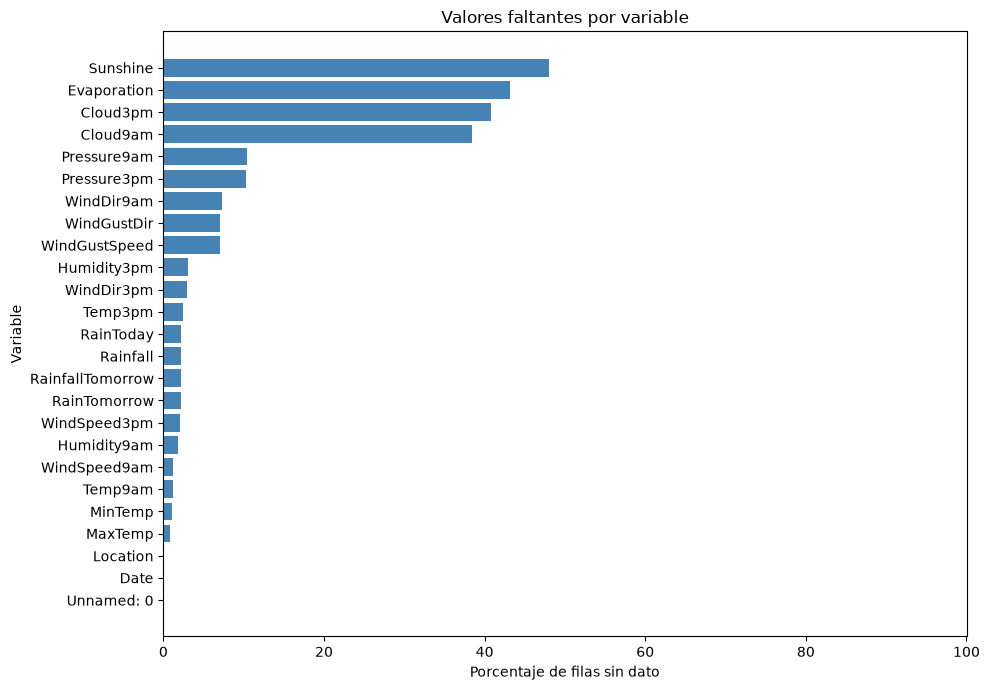

In [ ]:
# Calculo y grafico el porcentaje de faltantes para comparar variables en la misma escala.
fig, ax = plt.subplots(figsize=(10, 7))
faltantes = pd.DataFrame({"porcentaje": df.isna().mean() * 100})
faltantes_ordenados = faltantes.sort_values("porcentaje")
ax.barh(faltantes_ordenados.index, faltantes_ordenados["porcentaje"], color="steelblue")
ax.set_title("Valores faltantes por variable")
ax.set_xlabel("Porcentaje de filas sin dato")
ax.set_ylabel("Variable")
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

### Análisis y decisión sobre los faltantes

Conservamos `Sunshine`, `Evaporation`, `Cloud3pm` y `Cloud9am` en el conjunto de datos porque describen condiciones meteorológicas que pueden aportar información sobre la lluvia: horas de sol, evaporación y cobertura de nubes en dos momentos del día. No eliminaremos las filas por tener faltante en alguna de estas cuatro columnas. Si lo hiciéramos, perderíamos 82.854 registros (56,98 % del archivo); entre las filas con `RainTomorrow` conocido, solo conservaríamos 62.349 (43,86 %). Además, los faltantes varían por ubicación y año. El tratamiento de estos predictores se definirá más adelante, después de separar entrenamiento y prueba.

Se excluirán del conjunto de modelado las filas que no tengan valor en `RainTomorrow`. Esta columna es la variable objetivo: sin conocer si llovió al día siguiente, no hay una respuesta observada con la cual entrenar el modelo ni comprobar después si acertó. Tampoco corresponde completar esa etiqueta con una moda o una mediana, porque eso asignaría una respuesta no observada y alteraría la distribución de clases.

Esta decisión se aplica a las filas sin etiqueta. Los faltantes en las variables que describen las condiciones del día se analizarán por separado y, si se conservan, se tratarán durante el preprocesamiento. Una mediana o una moda puede servir como estrategia para ciertos predictores, pero no reemplaza el valor faltante de `RainTomorrow`.

### Visualización de datos

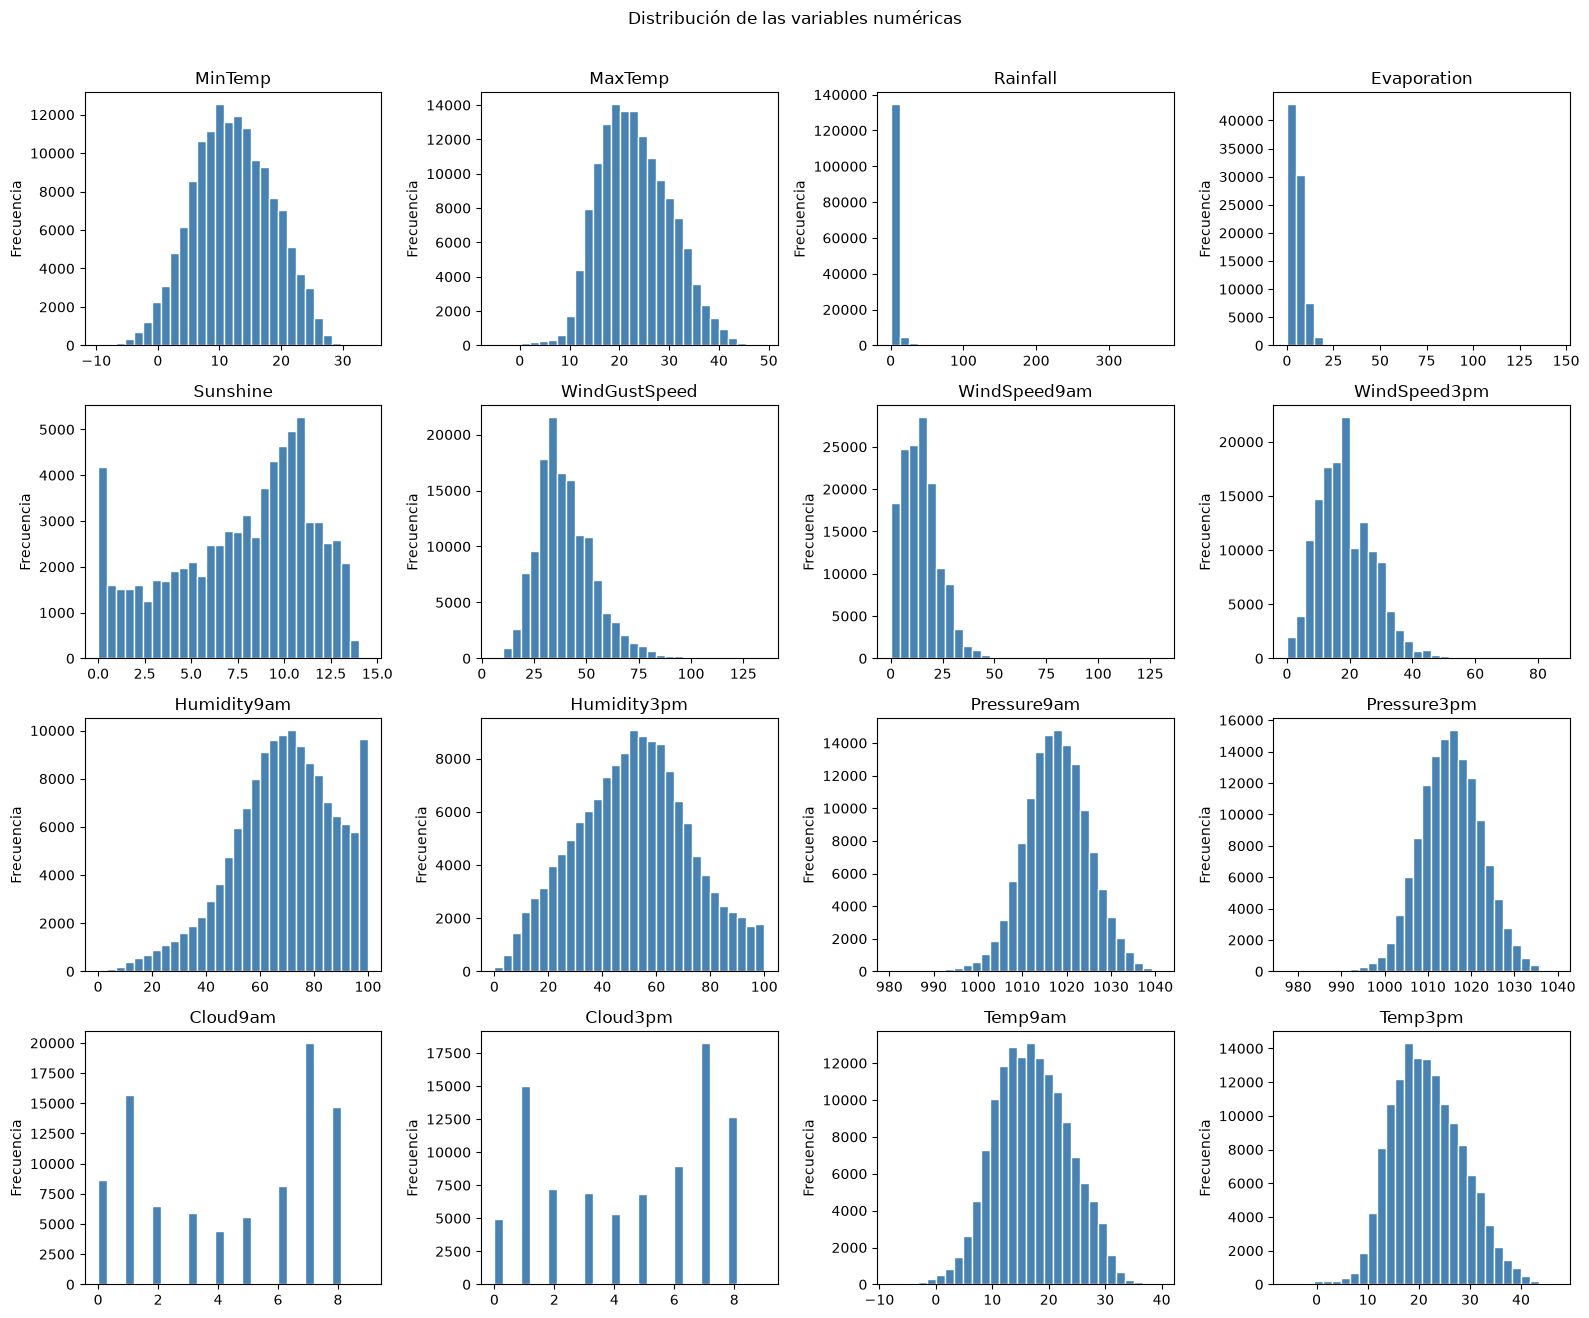

In [ ]:
# Grafico las distribuciones de los predictores numéricos definidos en el EDA.
variables_hist = columnas_predictoras_numericas

fig, axes = plt.subplots(4, 4, figsize=(16, 13))
for ax, columna in zip(axes.flat, variables_hist):
    datos = df[columna].dropna()
    ax.hist(datos, bins=30, color="steelblue", edgecolor="white")
    ax.set_title(columna)
    ax.set_ylabel("Frecuencia")

for ax in axes.flat[len(variables_hist):]:
    ax.set_visible(False)

fig.suptitle("Distribución de las variables numéricas", y=1.01)
plt.tight_layout()
plt.show()

Para observar asociaciones entre predictores, usamos dos diagramas de dispersión. El color representa la clase observada de RainTomorrow. Se toman hasta 8.000 observaciones completas por gráfico con una semilla fija para mantener la figura legible y reproducible; este muestreo se usa únicamente para graficar.

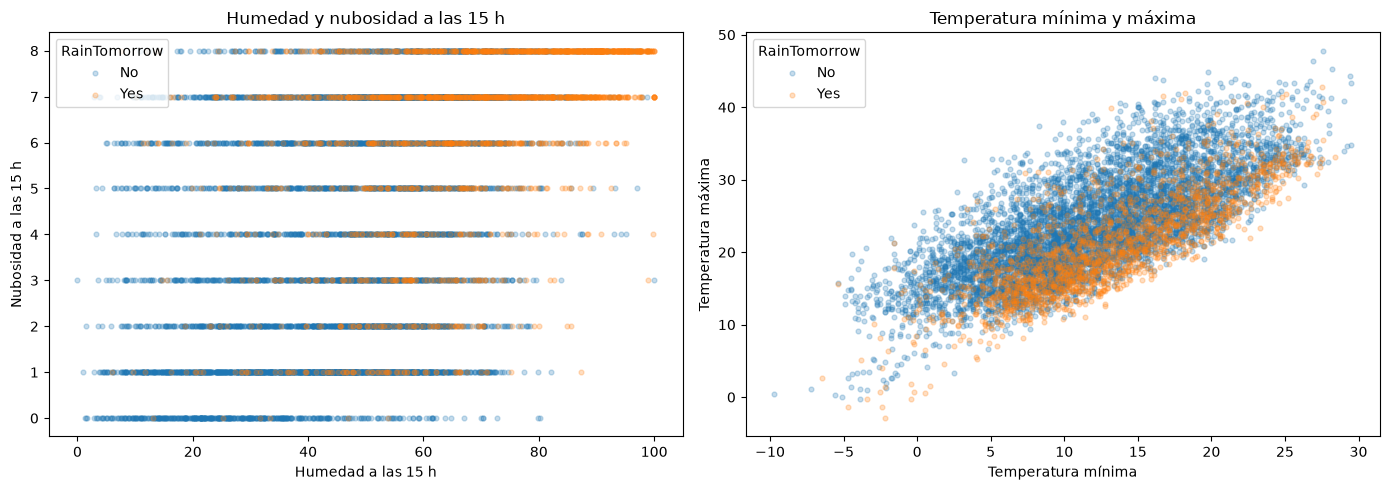

In [ ]:
# Comparo humedad con nubosidad y temperatura mínima con máxima, coloreando por la clase objetivo.
colores_clase = {"No": "tab:blue", "Yes": "tab:orange"}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

datos_humedad_nubes = df.dropna(subset=["Humidity3pm", "Cloud3pm", "RainTomorrow"])
if len(datos_humedad_nubes) > 8000:
    datos_humedad_nubes = datos_humedad_nubes.sample(n=8000, random_state=42)

for clase, color in colores_clase.items():
    grupo = datos_humedad_nubes[datos_humedad_nubes["RainTomorrow"] == clase]
    axes[0].scatter(
        grupo["Humidity3pm"], grupo["Cloud3pm"],
        s=12, alpha=0.25, color=color, label=clase
    )
axes[0].set_title("Humedad y nubosidad a las 15 h")
axes[0].set_xlabel("Humedad a las 15 h")
axes[0].set_ylabel("Nubosidad a las 15 h")
axes[0].legend(title="RainTomorrow", loc="upper left")

datos_temperaturas = df.dropna(subset=["MinTemp", "MaxTemp", "RainTomorrow"])
if len(datos_temperaturas) > 8000:
    datos_temperaturas = datos_temperaturas.sample(n=8000, random_state=42)

for clase, color in colores_clase.items():
    grupo = datos_temperaturas[datos_temperaturas["RainTomorrow"] == clase]
    axes[1].scatter(
        grupo["MinTemp"], grupo["MaxTemp"],
        s=12, alpha=0.25, color=color, label=clase
    )
axes[1].set_title("Temperatura mínima y máxima")
axes[1].set_xlabel("Temperatura mínima")
axes[1].set_ylabel("Temperatura máxima")
axes[1].legend(title="RainTomorrow")

plt.tight_layout()
plt.show()

Los diagramas de caja permiten comparar la mediana y el rango intercuartílico de las cuatro variables con mayor proporción de faltantes, separando las observaciones según RainTomorrow. Se ocultan los puntos extremos para que la zona central sea legible; los valores siguen presentes en el conjunto de datos. Los tamaños de muestra se indican en las etiquetas del eje horizontal.

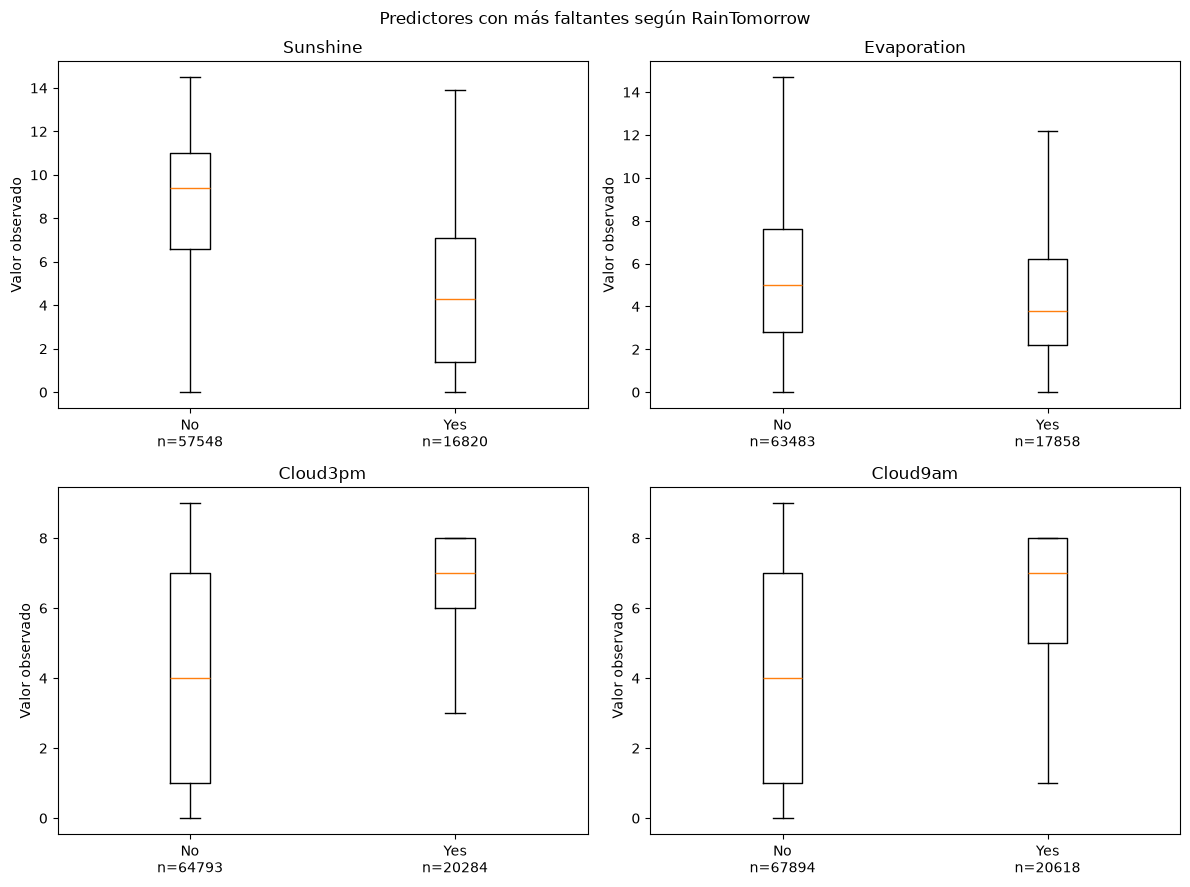

In [ ]:
# Comparo por clase las distribuciones de las cuatro variables con mayor proporción de faltantes.
variables_caja = ["Sunshine", "Evaporation", "Cloud3pm", "Cloud9am"]
clases = ["No", "Yes"]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, columna in zip(axes.flat, variables_caja):
    valores_por_clase = [
        df.loc[df["RainTomorrow"] == clase, columna].dropna()
        for clase in clases
    ]
    ax.boxplot(valores_por_clase, showfliers=False)
    ax.set_xticks([1, 2])
    ax.set_xticklabels([
        f"{clase}\nn={len(valores)}"
        for clase, valores in zip(clases, valores_por_clase)
    ])
    ax.set_title(columna)
    ax.set_ylabel("Valor observado")

fig.suptitle("Predictores con más faltantes según RainTomorrow")
plt.tight_layout()
plt.show()

### Lectura de las visualizaciones

Los histogramas muestran que las variables tienen escalas y distribuciones distintas. Por ejemplo, Rainfall concentra muchas observaciones cerca de cero y presenta una cola hacia valores altos; Cloud9am y Cloud3pm toman valores discretos. Esto conviene tenerlo en cuenta al decidir el preprocesamiento.

En los diagramas de caja, la mediana de Sunshine es 9,4 horas para RainTomorrow = No y 4,3 para RainTomorrow = Yes. Para Cloud3pm y Cloud9am, las medianas son 4 y 7, respectivamente; para Evaporation, son 5 y 3,8. En los diagramas de dispersión se observa una relación creciente entre temperatura mínima y máxima, mientras que humedad y nubosidad forman bandas por los valores discretos de nubosidad. Las clases se superponen: estas figuras describen asociaciones del conjunto y no demuestran causalidad ni evalúan el desempeño de un modelo.

Los tamaños de muestra de los diagramas de caja varían porque se omiten los registros sin dato en cada predictor. No se imputaron valores para construir las figuras.

### ¿Está balanceado el dataset?

Para responderlo, observamos la distribución de la variable objetivo RainTomorrow. El cálculo usa únicamente las filas con etiqueta conocida: las observaciones sin RainTomorrow no aportan una clase al conteo y se conservan en df para las decisiones posteriores.

,cantidad,porcentaje
RainTomorrow,,
No,110281,77.58
Yes,31872,22.42


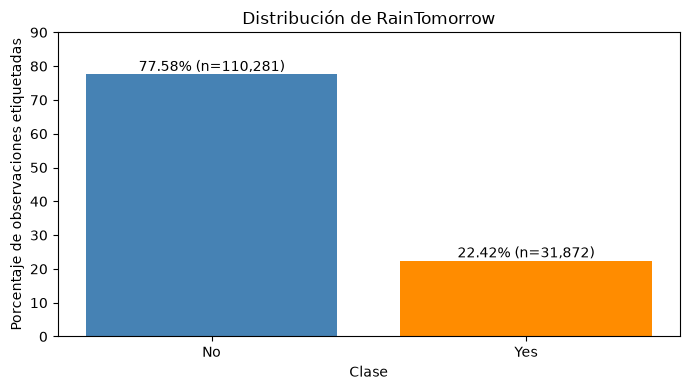

Referencia de mayoría (predecir siempre No): accuracy = 77.58%; recall de Yes = 0.00%.
Filas sin etiqueta excluidas de este conteo: 3,259.


In [ ]:
# Cuento las clases conocidas y comparo su proporción con un clasificador constante de referencia.
clases_objetivo = ["No", "Yes"]
conteos_objetivo = (
    df["RainTomorrow"]
    .dropna()
    .value_counts()
    .reindex(clases_objetivo, fill_value=0)
)
total_etiquetado = conteos_objetivo.sum()
balance_objetivo = pd.DataFrame({
    "cantidad": conteos_objetivo,
    "porcentaje": conteos_objetivo / total_etiquetado * 100,
})
balance_objetivo.index.name = "RainTomorrow"
display(balance_objetivo.round({"porcentaje": 2}))

fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(
    balance_objetivo.index,
    balance_objetivo["porcentaje"],
    color=["steelblue", "darkorange"],
)
for barra, porcentaje, cantidad in zip(
    barras, balance_objetivo["porcentaje"], balance_objetivo["cantidad"]
):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 1,
        f"{porcentaje:.2f}% (n={cantidad:,})",
        ha="center",
    )
ax.set_title("Distribución de RainTomorrow")
ax.set_xlabel("Clase")
ax.set_ylabel("Porcentaje de observaciones etiquetadas")
ax.set_ylim(0, 90)
plt.tight_layout()
plt.show()

clase_mayoritaria = conteos_objetivo.idxmax()
accuracy_referencia = conteos_objetivo.max() / total_etiquetado
print(
    f"Referencia de mayoría (predecir siempre {clase_mayoritaria}): "
    f"accuracy = {accuracy_referencia:.2%}; recall de Yes = 0.00%."
)
print(f"Filas sin etiqueta excluidas de este conteo: {df['RainTomorrow'].isna().sum():,}.")

El conjunto no está balanceado respecto de la variable objetivo. Entre las 142.153 filas con etiqueta conocida, 110.281 (77,58 %) corresponden a RainTomorrow = No y 31.872 (22,42 %) a RainTomorrow = Yes; hay aproximadamente 3,46 casos de la clase mayoritaria por cada caso de la minoritaria. Las 3.259 filas sin etiqueta no se incluyen en estas proporciones.

La distribución importa porque un clasificador que siempre predijera No alcanzaría una accuracy de 77,58 %, pero tendría recall de 0 % para los días lluviosos. Por eso, como se trabaja en la unidad de métricas de clasificación, la accuracy por sí sola no alcanza para evaluar el desempeño: luego habrá que revisar métricas por clase y la matriz de confusión.


### Codificación de variables categóricas

Para la predicción usaremos Location, WindGustDir, WindDir9am, WindDir3pm y RainToday como variables categóricas. RainTomorrow es la etiqueta, no un predictor, y Date se usa para ordenar las observaciones y separar entrenamiento y prueba, pero no como predictor.

In [ ]:
# Resumo las variables categóricas candidatas y algunos de sus valores observados.
columnas_categoricas = [
    "Location",
    "WindGustDir",
    "WindDir9am",
    "WindDir3pm",
    "RainToday",
]
resumen_categoricas = pd.DataFrame({
    "valores distintos": df[columnas_categoricas].nunique(dropna=True),
    "faltantes": df[columnas_categoricas].isna().sum(),
    "ejemplos": {
        columna: ", ".join(
            df[columna].dropna().astype(str).unique()[:5]
        )
        for columna in columnas_categoricas
    },
})
display(resumen_categoricas)

,valores distintos,faltantes,ejemplos
Location,49,0,"Albury, BadgerysCreek, Cobar, CoffsHarbour, Moree"
WindGustDir,16,10316,"W, WNW, WSW, NE, NNW"
WindDir9am,16,10562,"W, NNW, SE, ENE, SW"
WindDir3pm,16,4226,"WNW, WSW, E, NW, W"
RainToday,2,3260,"No, Yes"


Estas variables son nominales: sus categorías no tienen un orden numérico natural. Por eso usamos pd.get_dummies, que crea una columna de 0 y 1 por categoría, y no asignamos números enteros arbitrarios a direcciones de viento o ubicaciones. Usamos drop_first=True para eliminar una categoría por variable, ya que queda determinada por las demás. Los valores faltantes de estas columnas se conservarán como una categoría propia.

La codificación se hace después de separar entrenamiento y prueba, y las columnas de prueba se alinean con las de entrenamiento.

### Matriz de correlación de variables

Calculamos correlaciones de Pearson entre los predictores numéricos y la etiqueta. Para incluir RainTomorrow en el análisis, usamos una copia temporal con No = 0 y Yes = 1; esta codificación solo se utiliza en la matriz, no modifica df ni reemplaza la codificación prevista para el modelo.

Las filas sin RainTomorrow conocido se excluyen de esta matriz. No imputamos los faltantes: pandas calcula cada correlación con las observaciones disponibles para ese par, por lo que la cantidad de observaciones puede variar entre pares.

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainTomorrow
MinTemp,1.00,0.73,0.10,0.47,0.07,0.18,0.17,0.17,-0.23,0.01,-0.45,-0.46,0.08,0.02,0.90,0.70,0.08
MaxTemp,0.73,1.00,-0.07,0.59,0.47,0.07,0.01,0.05,-0.50,-0.51,-0.33,-0.43,-0.29,-0.28,0.88,0.98,-0.16
Rainfall,0.10,-0.07,1.00,-0.06,-0.23,0.13,0.09,0.06,0.22,0.25,-0.17,-0.13,0.20,0.17,0.01,-0.08,0.24
Evaporation,0.47,0.59,-0.06,1.00,0.37,0.20,0.19,0.13,-0.50,-0.39,-0.27,-0.29,-0.19,-0.18,0.54,0.57,-0.12
Sunshine,0.07,0.47,-0.23,0.37,1.00,-0.03,0.01,0.06,-0.49,-0.63,0.04,-0.02,-0.68,-0.70,0.29,0.49,-0.45
WindGustSpeed,0.18,0.07,0.13,0.20,-0.03,1.00,0.60,0.68,-0.21,-0.03,-0.46,-0.41,0.07,0.11,0.15,0.03,0.23
WindSpeed9am,0.17,0.01,0.09,0.19,0.01,0.60,1.00,0.51,-0.27,-0.03,-0.23,-0.17,0.02,0.05,0.13,0.00,0.09
WindSpeed3pm,0.17,0.05,0.06,0.13,0.06,0.68,0.51,1.00,-0.14,0.02,-0.29,-0.25,0.05,0.03,0.16,0.03,0.09
Humidity9am,-0.23,-0.50,0.22,-0.50,-0.49,-0.21,-0.27,-0.14,1.00,0.66,0.14,0.19,0.45,0.36,-0.47,-0.50,0.26
Humidity3pm,0.01,-0.51,0.25,-0.39,-0.63,-0.03,-0.03,0.02,0.66,1.00,-0.03,0.05,0.52,0.52,-0.22,-0.56,0.44


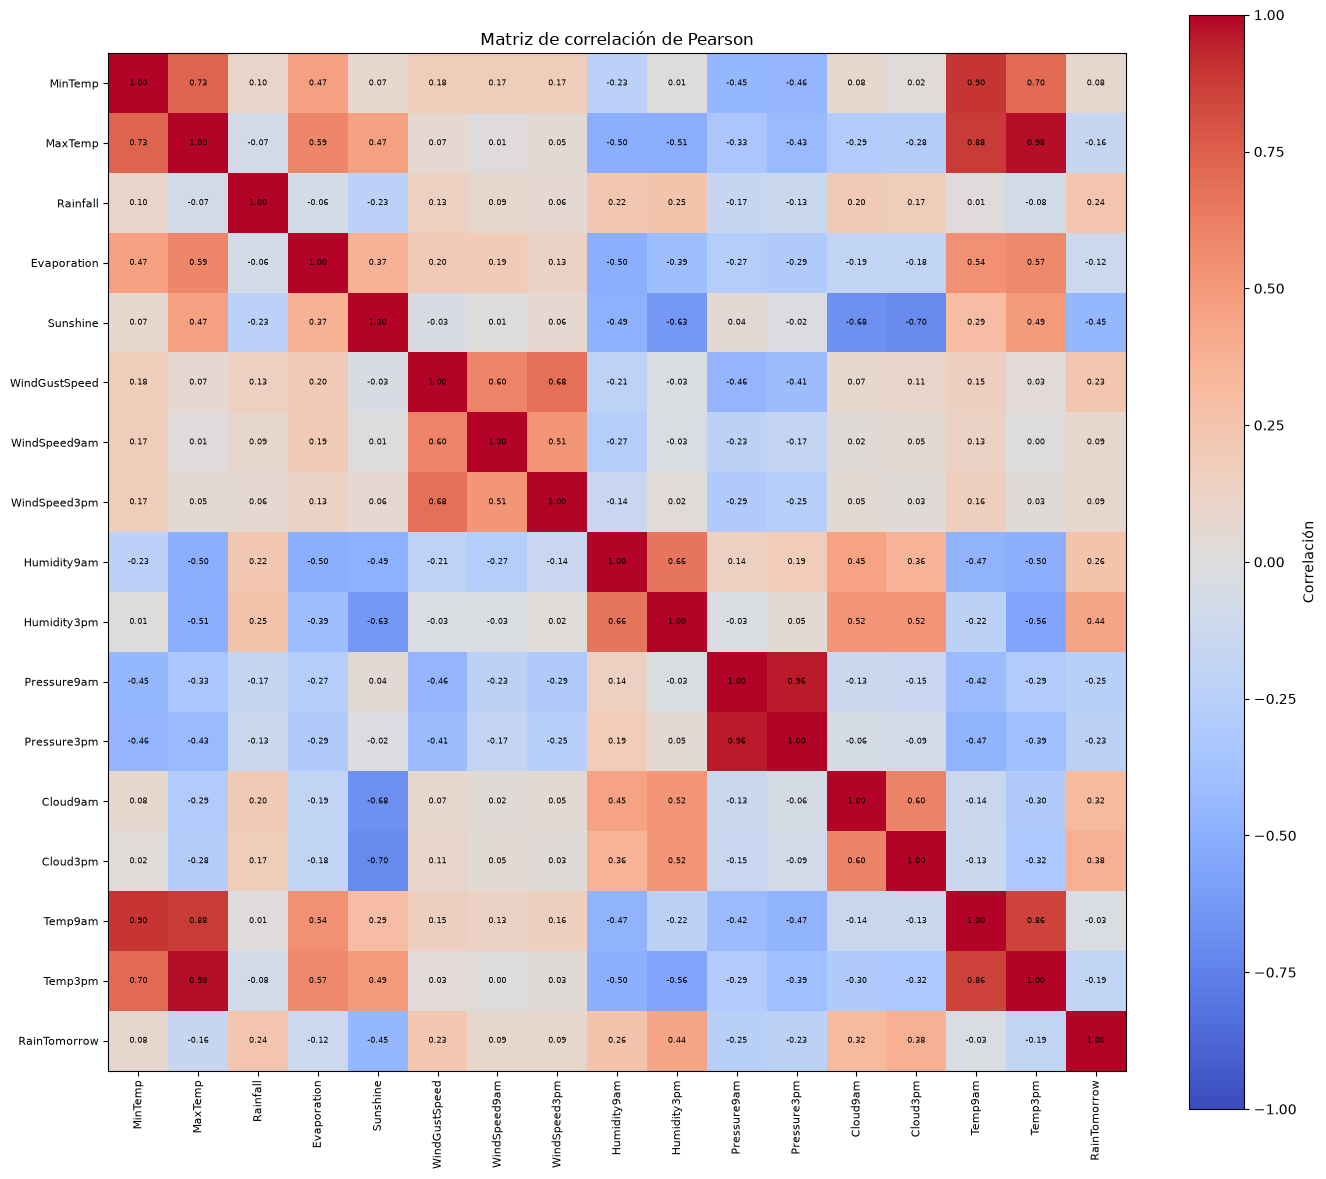

,correlación con RainTomorrow,observaciones válidas
Sunshine,-0.451,74368
Humidity3pm,0.445,138544
Cloud3pm,0.382,85077
Cloud9am,0.317,88512
Humidity9am,0.256,140379
Pressure9am,-0.246,128143
Rainfall,0.239,140747
WindGustSpeed,0.233,132885
Pressure3pm,-0.226,128176
Temp3pm,-0.192,139428


In [ ]:
# Calculo y grafico las correlaciones de Pearson sin modificar el conjunto original.
variables_numericas = columnas_predictoras_numericas
datos_correlacion = df.loc[
    df["RainTomorrow"].notna(), variables_numericas
].copy()
datos_correlacion["RainTomorrow"] = (
    df.loc[df["RainTomorrow"].notna(), "RainTomorrow"]
    .map({"No": 0, "Yes": 1})
)

matriz_correlacion = datos_correlacion.corr(method="pearson")
display(matriz_correlacion.round(2))

fig, ax = plt.subplots(figsize=(14, 12))
imagen = ax.imshow(
    matriz_correlacion,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
)
etiquetas = matriz_correlacion.columns
ax.set_xticks(range(len(etiquetas)))
ax.set_yticks(range(len(etiquetas)))
ax.set_xticklabels(etiquetas, rotation=90, fontsize=8)
ax.set_yticklabels(etiquetas, fontsize=8)
for fila in range(len(etiquetas)):
    for columna in range(len(etiquetas)):
        ax.text(
            columna,
            fila,
            f"{matriz_correlacion.iloc[fila, columna]:.2f}",
            ha="center",
            va="center",
            fontsize=6,
        )
ax.set_title("Matriz de correlación de Pearson")
fig.colorbar(imagen, ax=ax, label="Correlación")
plt.tight_layout()
plt.show()

asociaciones_objetivo = pd.DataFrame({
    "correlación con RainTomorrow": matriz_correlacion["RainTomorrow"].drop("RainTomorrow"),
    "observaciones válidas": datos_correlacion.drop(columns="RainTomorrow").count(),
})
orden = asociaciones_objetivo["correlación con RainTomorrow"].abs().sort_values(
    ascending=False
).index
display(asociaciones_objetivo.loc[orden].round(3))

La matriz muestra asociaciones lineales que pueden orientar la comprensión del conjunto. Las correlaciones más altas con RainTomorrow son Sunshine (−0,451), Humidity3pm (0,445), Cloud3pm (0,382) y Cloud9am (0,317). Entre predictores, MaxTemp y Temp3pm presentan una correlación de 0,98, y Pressure9am y Pressure3pm una de 0,96; son mediciones relacionadas y podrían aportar información parcialmente redundante.

Estas asociaciones no implican causalidad ni bastan, por sí solas, para eliminar variables. La matriz también debe leerse considerando que cada par puede usar una cantidad distinta de filas debido a los faltantes. La correlación de Pearson resume relaciones lineales y puede no describir relaciones más complejas.

### Estandarización/escalado de datos

Los predictores numéricos tienen unidades y rangos distintos, lo que puede afectar a modelos que regularizan sus coeficientes. En el EDA también observamos distribuciones asimétricas y valores extremos. Usaremos `RobustScaler`, que centra con la mediana y escala por el rango intercuartílico; los extremos no determinan esos parámetros y permanecen en los datos transformados.

Como el objetivo es predecir días futuros, reservamos para prueba el tramo cronológico más reciente. Ajustamos el escalador solo con entrenamiento y luego lo aplicamos a prueba. Las variables categóricas quedan sin escalar porque se codificarán por separado. Los faltantes numéricos siguen como `NaN`; el escalado no los imputa.

In [ ]:
# Separo cronológicamente las filas etiquetadas y escalo los predictores numéricos con entrenamiento.
datos_etiquetados = df.loc[df["RainTomorrow"].notna()].copy()
columnas_predictoras = columnas_predictoras_numericas + columnas_categoricas
X = datos_etiquetados[columnas_predictoras].copy()
y = datos_etiquetados["RainTomorrow"].copy()

fecha_corte = datos_etiquetados["Date"].quantile(0.80)
mascara_entrenamiento = datos_etiquetados["Date"] <= fecha_corte
X_train = X.loc[mascara_entrenamiento].copy()
X_test = X.loc[~mascara_entrenamiento].copy()
y_train = y.loc[mascara_entrenamiento].copy()
y_test = y.loc[~mascara_entrenamiento].copy()

pipeline_escalado = Pipeline(steps=[("escalador", RobustScaler())])
X_train_escalado = X_train.copy()
X_test_escalado = X_test.copy()
X_train_escalado.loc[:, columnas_predictoras_numericas] = pipeline_escalado.fit_transform(
    X_train[columnas_predictoras_numericas]
)
X_test_escalado.loc[:, columnas_predictoras_numericas] = pipeline_escalado.transform(
    X_test[columnas_predictoras_numericas]
)


resumen_train_escalado = (
    X_train_escalado[columnas_predictoras_numericas]
    .describe()
    .T[["min", "50%", "max"]]
    .round(2)
)
resumen_test_escalado = (
    X_test_escalado[columnas_predictoras_numericas]
    .describe()
    .T[["min", "50%", "max"]]
    .round(2)
)
display(pd.concat({
    "Entrenamiento escalado": resumen_train_escalado,
    "Prueba escalada": resumen_test_escalado,
}, axis=1))

Entrenamiento escalado              Prueba escalada        \
                                 min  50%     max             min   50%   
MinTemp                        -2.34  0.0    2.42           -2.21  0.13   
MaxTemp                        -2.59  0.0    2.65           -2.71  0.16   
Rainfall                        0.00  0.0  463.75            0.00  0.00   
Evaporation                    -1.00  0.0   16.91           -1.00  0.22   
Sunshine                       -1.45  0.0    1.02           -1.45  0.05   
WindGustSpeed                  -1.88  0.0    5.71           -1.88  0.00   
WindSpeed9am                   -1.08  0.0    6.25           -1.08  0.00   
WindSpeed3pm                   -1.50  0.0    5.67           -1.50  0.00   
Humidity9am                    -2.66  0.0    1.15           -2.62  0.01   
Humidity3pm                    -1.80  0.0    1.66           -1.75 -0.00   
Pressure9am                    -3.91  0.0    2.44           -3.78 -0.08   
Pressure3pm                    -3.69  0.0    2.54           -3.96 -0.08   
Cloud9am                       -0.83  0.0    0.67           -0.83  0.17   
Cloud3pm                       -1.00  0.0    0.80           -1.00  0.20   
Temp9am                        -2.50  0.0    2.53           -2.66  0.13   
Temp3pm                        -2.65  0.0    2.68           -2.75  0.13   

                       
                  max  
MinTemp          2.15  
MaxTemp          2.50  
Rainfall       281.25  
Evaporation     30.52  
Sunshine         1.05  
WindGustSpeed    4.94  
WindSpeed9am     9.75  
WindSpeed3pm     3.83  
Humidity9am      1.15  
Humidity3pm      1.66  
Pressure9am      2.35  
Pressure3pm      2.19  
Cloud9am         0.50  
Cloud3pm         0.60  
Temp9am          2.33  
Temp3pm          2.69

### Validación train-test

La tabla permite revisar el período y la proporción de clases en cada conjunto. El tramo de prueba corresponde a fechas posteriores a las usadas para entrenar y queda reservado para la evaluación final. Si más adelante ajustamos hiperparámetros, la validación cruzada se hará dentro de entrenamiento para no usar el conjunto de prueba durante esa selección.

In [ ]:
# Compruebo el período y la proporción de clases en cada conjunto.
fechas_train = datos_etiquetados.loc[X_train.index, "Date"]
fechas_test = datos_etiquetados.loc[X_test.index, "Date"]
resumen_validacion = pd.DataFrame({
    "filas": [len(X_train), len(X_test)],
    "fecha inicial": [fechas_train.min().date(), fechas_test.min().date()],
    "fecha final": [fechas_train.max().date(), fechas_test.max().date()],
    "RainTomorrow = No (%)": [
        (y_train == "No").mean() * 100,
        (y_test == "No").mean() * 100,
    ],
    "RainTomorrow = Yes (%)": [
        (y_train == "Yes").mean() * 100,
        (y_test == "Yes").mean() * 100,
    ],
}, index=["Entrenamiento", "Prueba"])
display(resumen_validacion.round({
    "RainTomorrow = No (%)": 2,
    "RainTomorrow = Yes (%)": 2,
}))

,filas,fecha inicial,fecha final,RainTomorrow = No (%),RainTomorrow = Yes (%)
Entrenamiento,113748,2007-11-01,2015-11-09,77.56,22.44
Prueba,28405,2015-11-10,2017-06-24,77.67,22.33


El corte queda en el 9 de noviembre de 2015: entrenamiento reúne 113.748 filas hasta esa fecha y prueba 28.405 filas desde el día siguiente. La proporción de RainTomorrow = Yes es 22,44 % en entrenamiento y 22,33 % en prueba; la de No es 77,56 % y 77,67 %, respectivamente. La partición respeta el orden temporal: entrenamiento incluye las fechas anteriores al corte y prueba, las posteriores. Las proporciones de clases son similares en ambos períodos.

## 2. Regresión logística

### Preprocesamiento

Para la regresión logística necesitamos que todas las columnas sean numéricas y no tengan faltantes. Partimos de los datos escalados con RobustScaler en el ejercicio 1, donde los faltantes numéricos quedaron como NaN.

En las numéricas, imputamos los faltantes con la mediana de entrenamiento. Elegimos la mediana y no la media porque varias variables son asimétricas o tienen valores extremos, como Rainfall y Evaporation. Como RobustScaler centra cada variable en su mediana, la mediana de cada columna escalada en entrenamiento es 0.

En las categóricas, reemplazamos los faltantes por la categoría "Faltante" y aplicamos pd.get_dummies con drop_first=True. Si en prueba falta alguna categoría, reindex agrega esa columna con ceros para que entrenamiento y prueba tengan las mismas columnas y en el mismo orden.

Las medianas se calculan solo con X_train y se aplican a ambos conjuntos.

In [ ]:
# Imputo faltantes con valores de entrenamiento y codifico las categóricas con get_dummies.
y_train_bin = (y_train == "Yes").astype(int)
y_test_bin = (y_test == "Yes").astype(int)

medianas_train = X_train_escalado[columnas_predictoras_numericas].median()
X_train_prep = X_train_escalado.copy()
X_test_prep = X_test_escalado.copy()
X_train_prep[columnas_predictoras_numericas] = X_train_prep[columnas_predictoras_numericas].fillna(medianas_train)
X_test_prep[columnas_predictoras_numericas] = X_test_prep[columnas_predictoras_numericas].fillna(medianas_train)

X_train_prep[columnas_categoricas] = X_train_prep[columnas_categoricas].fillna("Faltante")
X_test_prep[columnas_categoricas] = X_test_prep[columnas_categoricas].fillna("Faltante")

X_train_prep = pd.get_dummies(X_train_prep, columns=columnas_categoricas, drop_first=True, dtype=int)
X_test_prep = pd.get_dummies(X_test_prep, columns=columnas_categoricas, drop_first=True, dtype=int)
X_test_prep = X_test_prep.reindex(columns=X_train_prep.columns, fill_value=0)

print("Entrenamiento:", X_train_prep.shape, "Prueba:", X_test_prep.shape)

Entrenamiento: (113748, 114) Prueba: (28405, 114)


In [ ]:
# Cuento cuántas columnas dummy generó cada variable categórica.
conteo_dummies = pd.Series({
    columna: X_train_prep.columns.str.startswith(columna + "_").sum()
    for columna in columnas_categoricas
}, name="columnas")
display(conteo_dummies.to_frame())
print("Numéricas:", len(columnas_predictoras_numericas), "| Dummies:", conteo_dummies.sum())

,columnas
Location,48
WindGustDir,16
WindDir9am,16
WindDir3pm,16
RainToday,2


Numéricas: 16 | Dummies: 98


Después del preprocesamiento quedan 114 columnas: las 16 numéricas y 98 dummies. Location aporta 48 (49 ciudades menos la eliminada por drop_first), cada dirección de viento 16 (16 direcciones más "Faltante", menos una) y RainToday 2 (No, Yes y "Faltante", menos una).

### Entrenamiento

Entrenamos dos regresiones logísticas sobre los datos preprocesados. La primera usa los parámetros por defecto. La segunda usa class_weight="balanced", que le asigna más peso en la función de costo a los errores en la clase Yes, en proporción a lo poco frecuente que es. Como el dataset está desbalanceado, queremos ver si esto mejora la detección de días con lluvia.

Subimos max_iter a 1000 porque con el valor por defecto (100) el optimizador no llega a converger.

In [ ]:
# Entreno dos regresiones logísticas: una estándar y otra que compensa el desbalance.
modelos = {
    "Logística": LogisticRegression(max_iter=1000),
    "Logística balanceada": LogisticRegression(max_iter=1000, class_weight="balanced"),
}
for nombre, modelo in modelos.items():
    modelo.fit(X_train_prep, y_train_bin)
    print(f"{nombre}: {modelo.n_iter_[0]} iteraciones")

Logística: 294 iteraciones


Logística balanceada: 235 iteraciones


### Métricas

Como el dataset está desbalanceado, no alcanza con la accuracy. Calculamos precision, recall y F1 de la clase Yes, que es la que nos interesa detectar, el recall de la clase No y el AUC, que no depende del umbral.

Además investigamos tres métricas pensadas para clases desbalanceadas, a partir de la documentación de scikit-learn (https://scikit-learn.org/stable/modules/model_evaluation.html):

- Balanced accuracy: promedio del recall de cada clase. Un modelo que predice siempre No obtiene 0,5, mientras que su accuracy sería 0,78.
- Coeficiente de correlación de Matthews (MCC): usa las cuatro celdas de la matriz de confusión, (VP·VN − FP·FN) / √((VP+FP)(VP+FN)(VN+FP)(VN+FN)). Va de −1 a 1, vale 0 para un modelo que no es mejor que predecir una clase constante y solo es alto si el modelo acierta bien en ambas clases.
- Average precision: resume la curva precision-recall en un número. A diferencia del AUC, no usa los verdaderos negativos, así que no se ve favorecida por la gran cantidad de días sin lluvia. Su valor de referencia es la proporción de Yes (0,22).

Medimos todo en entrenamiento y en prueba para después comparar ambos conjuntos y evaluar el fitting.

In [ ]:
# Calculo las métricas de cada modelo en entrenamiento y prueba.
conjuntos = {
    "Entrenamiento": (X_train_prep, y_train_bin),
    "Prueba": (X_test_prep, y_test_bin),
}
filas_metricas = []
for nombre, modelo in modelos.items():
    for conjunto, (X_conjunto, y_conjunto) in conjuntos.items():
        y_pred = modelo.predict(X_conjunto)
        y_prob = modelo.predict_proba(X_conjunto)[:, 1]
        filas_metricas.append({
            "modelo": nombre,
            "conjunto": conjunto,
            "accuracy": accuracy_score(y_conjunto, y_pred),
            "precision (Yes)": precision_score(y_conjunto, y_pred),
            "recall (Yes)": recall_score(y_conjunto, y_pred),
            "F1 (Yes)": f1_score(y_conjunto, y_pred),
            "recall (No)": recall_score(y_conjunto, y_pred, pos_label=0),
            "AUC": roc_auc_score(y_conjunto, y_prob),
            "balanced accuracy": balanced_accuracy_score(y_conjunto, y_pred),
            "MCC": matthews_corrcoef(y_conjunto, y_pred),
            "average precision": average_precision_score(y_conjunto, y_prob),
        })

metricas = pd.DataFrame(filas_metricas).set_index(["modelo", "conjunto"])
display(metricas.round(3))

accuracy  precision (Yes)  recall (Yes)  \
modelo               conjunto                                                 
Logística            Entrenamiento     0.850            0.732         0.522   
                     Prueba            0.842            0.721         0.479   
Logística balanceada Entrenamiento     0.797            0.533         0.782   
                     Prueba            0.796            0.531         0.747   

                                    F1 (Yes)  recall (No)    AUC  \
modelo               conjunto                                      
Logística            Entrenamiento     0.609        0.945  0.875   
                     Prueba            0.575        0.947  0.860   
Logística balanceada Entrenamiento     0.634        0.801  0.876   
                     Prueba            0.620        0.810  0.861   

                                    balanced accuracy    MCC  \
modelo               conjunto                                  
Logística            Entrenamiento              0.733  0.531   
                     Prueba                     0.713  0.498   
Logística balanceada Entrenamiento              0.792  0.518   
                     Prueba                     0.778  0.499   

                                    average precision  
modelo               conjunto                          
Logística            Entrenamiento              0.710  
                     Prueba                     0.684  
Logística balanceada Entrenamiento              0.707  
                     Prueba                     0.681

In [ ]:
# Muestro precision, recall y F1 de ambas clases para cada modelo en prueba.
for nombre, modelo in modelos.items():
    print(nombre)
    print(classification_report(y_test_bin, modelo.predict(X_test_prep), target_names=["No", "Yes"]))

Logística
              precision    recall  f1-score   support

          No       0.86      0.95      0.90     22061
         Yes       0.72      0.48      0.58      6344

    accuracy                           0.84     28405
   macro avg       0.79      0.71      0.74     28405
weighted avg       0.83      0.84      0.83     28405

Logística balanceada
              precision    recall  f1-score   support

          No       0.92      0.81      0.86     22061
         Yes       0.53      0.75      0.62      6344

    accuracy                           0.80     28405
   macro avg       0.72      0.78      0.74     28405
weighted avg       0.83      0.80      0.81     28405



En prueba, la regresión logística estándar alcanza una accuracy de 0,842, por encima de la referencia de predecir siempre No (77,67 % en prueba). Sin embargo, su recall de Yes es 0,477: detecta menos de la mitad de los días con lluvia. La versión balanceada baja la accuracy a 0,796, pero sube el recall de Yes a 0,747. A cambio, la precision de Yes baja de 0,721 a 0,530, es decir, da más falsas alarmas. El F1 de Yes mejora de 0,574 a 0,621.

El AUC es prácticamente igual en los dos modelos (0,860 y 0,861). Esto indica que ambos ordenan los días según su probabilidad de lluvia casi de la misma forma, y lo que cambia es dónde queda el corte entre Yes y No. Por eso más adelante analizamos el umbral con la curva ROC.

Las métricas adicionales ayudan a separar estos dos efectos. La balanced accuracy favorece al modelo balanceado (0,779 contra 0,712 en prueba), porque premia el aumento del recall de Yes. En cambio, el MCC (0,497 y 0,500) y la average precision (0,684 y 0,681) son prácticamente iguales en ambos modelos y quedan muy por encima de sus valores de referencia (0 y 0,22). Esto confirma lo que muestra el AUC: los dos modelos tienen una capacidad de discriminación similar, y la diferencia está en el umbral de decisión.

### Matrices de confusión

Tomamos Yes como clase positiva. En la matriz, las filas indican el valor real y las columnas la predicción. Un falso positivo es un día en que el modelo predijo lluvia y no llovió (falsa alarma). Un falso negativo es un día en que llovió y el modelo predijo que no (lluvia sin aviso).

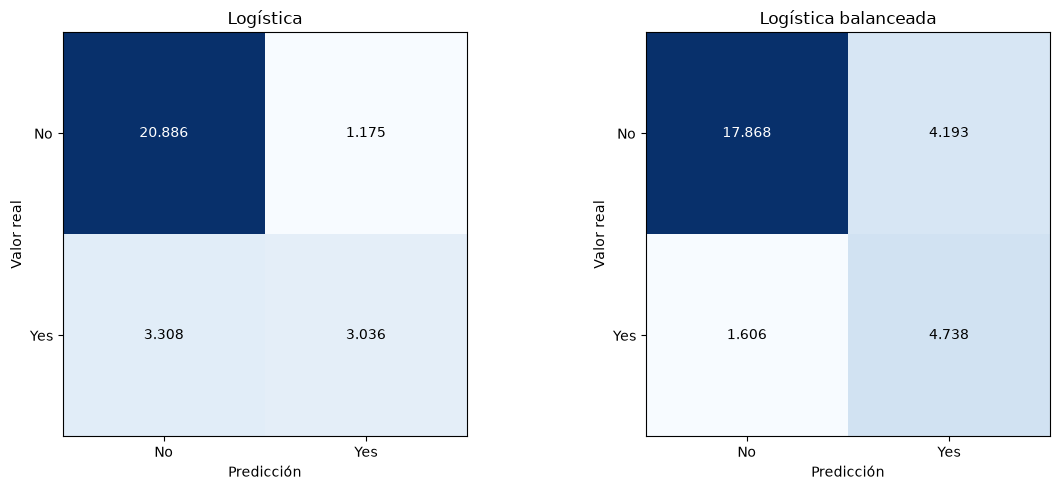

In [ ]:
# Defino una función para graficar matrices de confusión y la aplico a cada modelo en prueba.
etiquetas_clases = ["No", "Yes"]

def graficar_matriz_confusion(ax, matriz, titulo):
    ax.imshow(matriz, cmap="Blues")
    for fila in range(2):
        for columna in range(2):
            ax.text(
                columna,
                fila,
                f"{matriz[fila, columna]:,}".replace(",", "."),
                ha="center",
                va="center",
                color="white" if matriz[fila, columna] > matriz.max() / 2 else "black",
            )
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(etiquetas_clases)
    ax.set_yticklabels(etiquetas_clases)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Valor real")
    ax.set_title(titulo)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (nombre, modelo) in zip(axes, modelos.items()):
    matriz = confusion_matrix(y_test_bin, modelo.predict(X_test_prep))
    graficar_matriz_confusion(ax, matriz, nombre)
plt.tight_layout()
plt.show()

La regresión logística estándar tiene 3.317 falsos negativos y 1.173 falsos positivos: se equivoca sobre todo dejando pasar días con lluvia. La versión balanceada reduce los falsos negativos a 1.603, pero sube los falsos positivos a 4.196.

Cuál de los dos errores es más grave depende del uso del pronóstico. Un falso negativo significa que llueve sin aviso, por ejemplo, alguien sale sin paraguas o no protege una cosecha o un evento al aire libre. Un falso positivo es una falsa alarma: se suspende o se prepara algo que no hacía falta. Para un pronóstico de uso general consideramos más costoso el falso negativo, así que priorizamos el recall de Yes sin dejar que la precision caiga demasiado. Esto lo vamos a tener en cuenta al elegir el umbral.

### Curva ROC y elección del umbral

Los modelos predicen Yes cuando la probabilidad estimada es mayor o igual a 0,5, pero ese valor es solo el umbral por defecto. La curva ROC muestra, para todos los umbrales posibles, la tasa de verdaderos positivos (recall de Yes) contra la tasa de falsos positivos.

El umbral es una decisión sobre el modelo, así que no lo elegimos mirando el conjunto de prueba. Separamos el último 20 % de las fechas de entrenamiento como validación, con el mismo criterio cronológico que el split principal, y entrenamos los dos modelos con el resto. Sobre validación calculamos la curva ROC y elegimos el umbral que maximiza la diferencia entre la tasa de verdaderos positivos y la de falsos positivos (índice de Youden). Ese umbral corresponde al punto de la curva más alejado de la diagonal.

In [ ]:
# Separo el último tramo de entrenamiento como validación y entreno los modelos sin él.
fecha_corte_validacion = fechas_train.quantile(0.80)
mascara_subentrenamiento = fechas_train <= fecha_corte_validacion
X_subentrenamiento = X_train_prep.loc[mascara_subentrenamiento]
X_validacion = X_train_prep.loc[~mascara_subentrenamiento]
y_subentrenamiento = y_train_bin.loc[mascara_subentrenamiento]
y_validacion = y_train_bin.loc[~mascara_subentrenamiento]

modelos_validacion = {
    "Logística": LogisticRegression(max_iter=1000),
    "Logística balanceada": LogisticRegression(max_iter=1000, class_weight="balanced"),
}
for modelo in modelos_validacion.values():
    modelo.fit(X_subentrenamiento, y_subentrenamiento)

print("Subentrenamiento:", len(X_subentrenamiento), "| Validación:", len(X_validacion), "| Corte:", fecha_corte_validacion.date())

Subentrenamiento: 91027 | Validación: 22721 | Corte: 2014-07-17


Logística: umbral elegido = 0.199 (TPR = 0.760, FPR = 0.197); con 0,5: TPR = 0.463, FPR = 0.045
Logística balanceada: umbral elegido = 0.396 (TPR = 0.806, FPR = 0.241); con 0,5: TPR = 0.725, FPR = 0.167


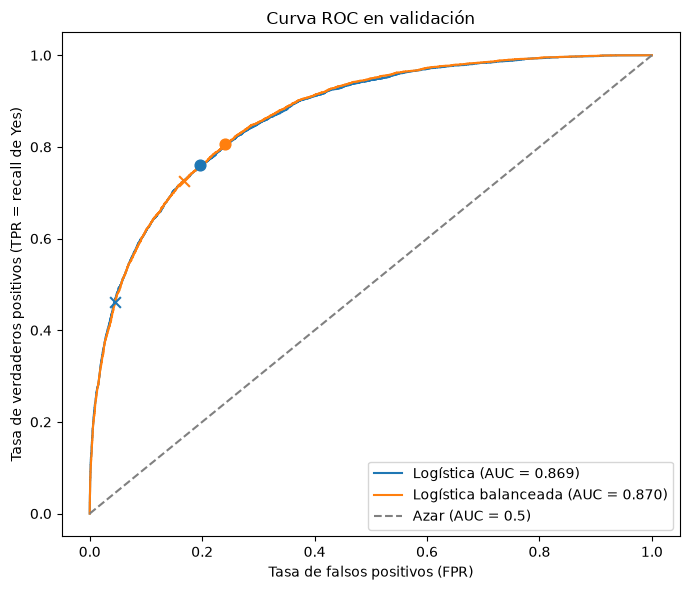

In [ ]:
# Grafico la curva ROC de cada modelo en validación y marco el umbral elegido y el de 0,5.
umbrales_elegidos = {}
fig, ax = plt.subplots(figsize=(7, 6))

for nombre, modelo in modelos_validacion.items():
    y_prob_validacion = modelo.predict_proba(X_validacion)[:, 1]
    fpr, tpr, umbrales = roc_curve(y_validacion, y_prob_validacion)
    indice_mejor = (tpr - fpr).argmax()
    umbrales_elegidos[nombre] = umbrales[indice_mejor]

    prediccion_05 = y_prob_validacion >= 0.5
    tpr_05 = (prediccion_05 & (y_validacion == 1)).sum() / (y_validacion == 1).sum()
    fpr_05 = (prediccion_05 & (y_validacion == 0)).sum() / (y_validacion == 0).sum()

    linea, = ax.plot(fpr, tpr, label=f"{nombre} (AUC = {auc(fpr, tpr):.3f})")
    ax.scatter(fpr[indice_mejor], tpr[indice_mejor], color=linea.get_color(), s=60, zorder=3)
    ax.scatter(fpr_05, tpr_05, color=linea.get_color(), marker="x", s=60, zorder=3)
    print(f"{nombre}: umbral elegido = {umbrales[indice_mejor]:.3f} "
          f"(TPR = {tpr[indice_mejor]:.3f}, FPR = {fpr[indice_mejor]:.3f}); "
          f"con 0,5: TPR = {tpr_05:.3f}, FPR = {fpr_05:.3f}")

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Azar (AUC = 0.5)")
ax.set_xlabel("Tasa de falsos positivos (FPR)")
ax.set_ylabel("Tasa de verdaderos positivos (TPR = recall de Yes)")
ax.set_title("Curva ROC en validación")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [ ]:
# Comparo en prueba el umbral de 0,5 con el umbral elegido en validación.
filas_umbral = []
for nombre, modelo in modelos.items():
    y_prob_prueba = modelo.predict_proba(X_test_prep)[:, 1]
    for umbral in [0.5, umbrales_elegidos[nombre]]:
        y_pred = (y_prob_prueba >= umbral).astype(int)
        vn, fp, fn, vp = confusion_matrix(y_test_bin, y_pred).ravel()
        filas_umbral.append({
            "modelo": nombre,
            "umbral": round(umbral, 3),
            "precision (Yes)": precision_score(y_test_bin, y_pred),
            "recall (Yes)": recall_score(y_test_bin, y_pred),
            "F1 (Yes)": f1_score(y_test_bin, y_pred),
            "balanced accuracy": balanced_accuracy_score(y_test_bin, y_pred),
            "falsos negativos": fn,
            "falsos positivos": fp,
        })

display(pd.DataFrame(filas_umbral).set_index(["modelo", "umbral"]).round(3))

precision (Yes)  recall (Yes)  F1 (Yes)  \
modelo               umbral                                            
Logística            0.500             0.721         0.479     0.575   
                     0.199             0.505         0.775     0.612   
Logística balanceada 0.500             0.531         0.747     0.620   
                     0.396             0.461         0.831     0.593   

                             balanced accuracy  falsos negativos  \
modelo               umbral                                        
Logística            0.500               0.713              3308   
                     0.199               0.778              1426   
Logística balanceada 0.500               0.778              1606   
                     0.396               0.776              1069   

                             falsos positivos  
modelo               umbral                    
Logística            0.500               1175  
                     0.199               4815  
Logística balanceada 0.500               4193  
                     0.396               6163

Las dos curvas ROC casi se superponen (AUC de 0,869 y 0,870 en validación). En el gráfico, la cruz marca el umbral 0,5 y el círculo, el umbral elegido.

¿Es 0,5 el mejor umbral? Para la regresión logística estándar, no. Con 0,5 detecta solo el 46 % de los días con lluvia en validación, mientras que con el umbral elegido (0,201) detecta el 76 %, a cambio de marcar como lluviosos el 19,5 % de los días sin lluvia. En la versión balanceada, el umbral elegido (0,421) queda más cerca de 0,5, porque class_weight ya desplazó las probabilidades hacia la clase Yes.

En prueba, el umbral elegido baja los falsos negativos del modelo estándar de 3.317 a 1.442, y sube los falsos positivos de 1.173 a 4.769. Con su umbral elegido, ambos modelos alcanzan prácticamente la misma balanced accuracy (0,778 y 0,779). Esto confirma que la diferencia principal entre ellos estaba en el punto de corte.

El índice de Youden no es la única forma de elegir el umbral. También se puede elegir el que maximiza el F1, fijar un recall mínimo de Yes y buscar el umbral con mayor precision que lo cumpla, o asignar un costo a cada tipo de error y minimizar el costo total. Elegimos Youden porque no requiere fijar costos arbitrarios y, en un dataset desbalanceado, favorece la detección de la clase minoritaria, que es la que más nos interesa.

### Fitting

Para evaluar el ajuste comparamos las métricas de entrenamiento y prueba. En la regresión logística estándar, la accuracy pasa de 0,850 a 0,842, el F1 de Yes de 0,609 a 0,574 y el AUC de 0,875 a 0,860. En la versión balanceada, la accuracy pasa de 0,797 a 0,796, el F1 de 0,634 a 0,621 y el AUC de 0,876 a 0,861. Las diferencias son chicas, así que no hay señales de sobreajuste: el modelo no memorizó el entrenamiento. Parte de la caída puede deberse a que prueba corresponde a un período posterior.

Tampoco hay un subajuste marcado: ambos modelos superan claramente la referencia de predecir siempre No en las métricas que miden la detección de lluvia, como la balanced accuracy (0,712 y 0,779 contra 0,5) y el MCC (0,497 y 0,500 contra 0). Sin embargo, el desempeño en entrenamiento también es limitado: incluso con los datos que vio, el modelo deja pasar muchos días de lluvia o genera muchas falsas alarmas. Esto es esperable en una regresión logística, cuya frontera de decisión es un hiperplano y no puede capturar relaciones más complejas entre las variables. Consideramos que el fitting es adecuado para este tipo de modelo. En los próximos ítems veremos si un modelo más flexible mejora estos resultados.

## 3. Modelo base

El modelo base sirve para tener un piso: si un modelo más complejo no lo supera, no aporta nada. En este ítem usamos dos tipos de referencia.

Primero, dos variantes de `DummyClassifier`, que no aprenden relaciones entre las variables. `most_frequent` predice siempre `No`, la clase mayoritaria. `stratified` sortea `Yes` y `No` respetando sus proporciones; fijamos `random_state=42` para que el sorteo sea siempre igual. La primera muestra qué accuracy se obtiene sin detectar ninguna lluvia; la segunda, qué pasa con un clasificador aleatorio.

Segundo, una regla simple: si `RainToday` es `Yes`, predecimos `Yes`; si no, `No`. Es la señal más obvia y está disponible a las 23:59, así que no usa información del futuro. Si falta `RainToday`, la regla predice `No`; en todo el dataset eso pasa en 3.260 filas (2,24 %). No usamos `RainfallTomorrow` porque es la lluvia del día siguiente.

No usamos un árbol ni otro modelo más complejo como base: eso ya sería un candidato a optimizar, no una referencia. Para comparar bien, usamos el mismo split y las mismas filas de prueba del ítem 2. El Dummy ignora las variables, así que el preprocesamiento no le cambia el resultado; la regla usa `RainToday` crudo. Por eso en este ítem no hace falta un pipeline. El pipeline va a ser útil en el ítem 4, cuando hagamos validación cruzada.

El enunciado dice "repetir los pasos del ítem 3"; por la numeración, entendemos que se refiere a los pasos de evaluación del ítem 2. Repetimos métricas, matrices de confusión y curvas, adaptadas a modelos que no entrenan.


In [ ]:
# Entreno los dos Dummy con los datos de entrenamiento
from sklearn.dummy import DummyClassifier

baselines = {
    "Dummy mayoritario": DummyClassifier(strategy="most_frequent"),
    "Dummy estratificado": DummyClassifier(strategy="stratified", random_state=42),
}
for nombre, modelo in baselines.items():
    # El Dummy ignora X, pero lo pasamos para mantener la interfaz de scikit-learn.
    modelo.fit(X_train_prep, y_train_bin)
    print(f"{nombre}: listo")


Dummy mayoritario: listo
Dummy estratificado: listo


In [ ]:
# Calculo las métricas de los modelos base en entrenamiento y prueba
def calcular_metricas(y_real, y_pred, y_score):
    return {
        "accuracy": accuracy_score(y_real, y_pred),
        "precision (Yes)": precision_score(y_real, y_pred, zero_division=0),
        "recall (Yes)": recall_score(y_real, y_pred, zero_division=0),
        "F1 (Yes)": f1_score(y_real, y_pred, zero_division=0),
        "recall (No)": recall_score(y_real, y_pred, pos_label=0, zero_division=0),
        "AUC": roc_auc_score(y_real, y_score),
        "balanced accuracy": balanced_accuracy_score(y_real, y_pred),
        "MCC": matthews_corrcoef(y_real, y_pred),
        "average precision": average_precision_score(y_real, y_score),
    }

conjuntos_baseline = {
    "Entrenamiento": (X_train_prep, X_train, y_train_bin),
    "Prueba": (X_test_prep, X_test, y_test_bin),
}
filas_baseline = []
for nombre, modelo in baselines.items():
    for conjunto, (X_prep, _, y_real) in conjuntos_baseline.items():
        y_pred = modelo.predict(X_prep)
        y_score = modelo.predict_proba(X_prep)[:, 1]
        filas_baseline.append({
            "modelo": nombre,
            "conjunto": conjunto,
            **calcular_metricas(y_real, y_pred, y_score),
        })
for conjunto, (_, X_crudo, y_real) in conjuntos_baseline.items():
    # Si RainToday falta, la comparación da False y la regla predice No.
    y_pred = (X_crudo["RainToday"] == "Yes").astype(int).to_numpy()
    filas_baseline.append({
        "modelo": "Regla RainToday",
        "conjunto": conjunto,
        **calcular_metricas(y_real, y_pred, y_pred),
    })

metricas_baseline = pd.DataFrame(filas_baseline).set_index(["modelo", "conjunto"])
display(metricas_baseline.round(3))


accuracy  precision (Yes)  recall (Yes)  \
modelo              conjunto                                                 
Dummy mayoritario   Entrenamiento     0.776            0.000         0.000   
                    Prueba            0.777            0.000         0.000   
Dummy estratificado Entrenamiento     0.652            0.225         0.225   
                    Prueba            0.651            0.219         0.219   
Regla RainToday     Entrenamiento     0.762            0.468         0.462   
                    Prueba            0.753            0.447         0.441   

                                   F1 (Yes)  recall (No)    AUC  \
modelo              conjunto                                      
Dummy mayoritario   Entrenamiento     0.000        1.000  0.500   
                    Prueba            0.000        1.000  0.500   
Dummy estratificado Entrenamiento     0.225        0.776  0.500   
                    Prueba            0.219        0.776  0.497   
Regla RainToday     Entrenamiento     0.465        0.848  0.655   
                    Prueba            0.444        0.843  0.642   

                                   balanced accuracy    MCC  average precision  
modelo              conjunto                                                    
Dummy mayoritario   Entrenamiento              0.500  0.000              0.224  
                    Prueba                     0.500  0.000              0.223  
Dummy estratificado Entrenamiento              0.500  0.001              0.225  
                    Prueba                     0.497 -0.005              0.222  
Regla RainToday     Entrenamiento              0.655  0.312              0.337  
                    Prueba                     0.642  0.285              0.322

In [ ]:
# Comparo en prueba los modelos base con las regresiones logísticas del ítem 2
comparacion_prueba = pd.concat([
    metricas_baseline.xs("Prueba", level="conjunto"),
    metricas.xs("Prueba", level="conjunto"),
])
display(comparacion_prueba.round(3))


,accuracy,precision (Yes),recall (Yes),F1 (Yes),recall (No),AUC,balanced accuracy,MCC,average precision
modelo,,,,,,,,,
Dummy mayoritario,0.777,0.000,0.000,0.000,1.000,0.500,0.500,0.000,0.223
Dummy estratificado,0.651,0.219,0.219,0.219,0.776,0.497,0.497,-0.005,0.222
Regla RainToday,0.753,0.447,0.441,0.444,0.843,0.642,0.642,0.285,0.322
Logística,0.842,0.721,0.479,0.575,0.947,0.860,0.713,0.498,0.684
Logística balanceada,0.796,0.531,0.747,0.620,0.810,0.861,0.778,0.499,0.681


En prueba, el Dummy mayoritario acierta el 77,7 % de las filas, pero no predice ningún `Yes`. Su recall, F1 y MCC dan 0, y la precision también da 0 porque no hay positivos predichos; usamos `zero_division=0` para que el cálculo no falle. Esa accuracy es la misma proporción de `No` del conjunto: no muestra ninguna capacidad de detectar lluvia. El Dummy estratificado baja a 0,651 y su AUC es 0,497: no distingue los días de lluvia de los secos.

La regla `RainToday` tiene menos accuracy (0,753), pero mejora las métricas de la clase `Yes`: precision 0,447, recall 0,441, F1 0,444, balanced accuracy 0,642, MCC 0,285 y average precision 0,322. Es una referencia más exigente que el Dummy, porque usa información real que ya conocemos a las 23:59.

La regresión logística estándar sigue arriba: accuracy ≈0,842, precision ≈0,72, recall ≈0,48, F1 ≈0,58, balanced accuracy ≈0,71, MCC ≈0,50 y average precision ≈0,68. La balanceada cambia el punto de corte: baja precision y sube recall. En los dos casos, el modelo entrenado mejora lo que consigue la regla de `RainToday`.

No optimizamos el umbral de los modelos base. El Dummy no da una probabilidad calibrada: sus puntajes son constantes o aleatorios. La regla ya tiene un corte fijo: `RainToday = Yes`. La comparación de umbrales queda para los modelos probabilísticos, como en el ítem 2.


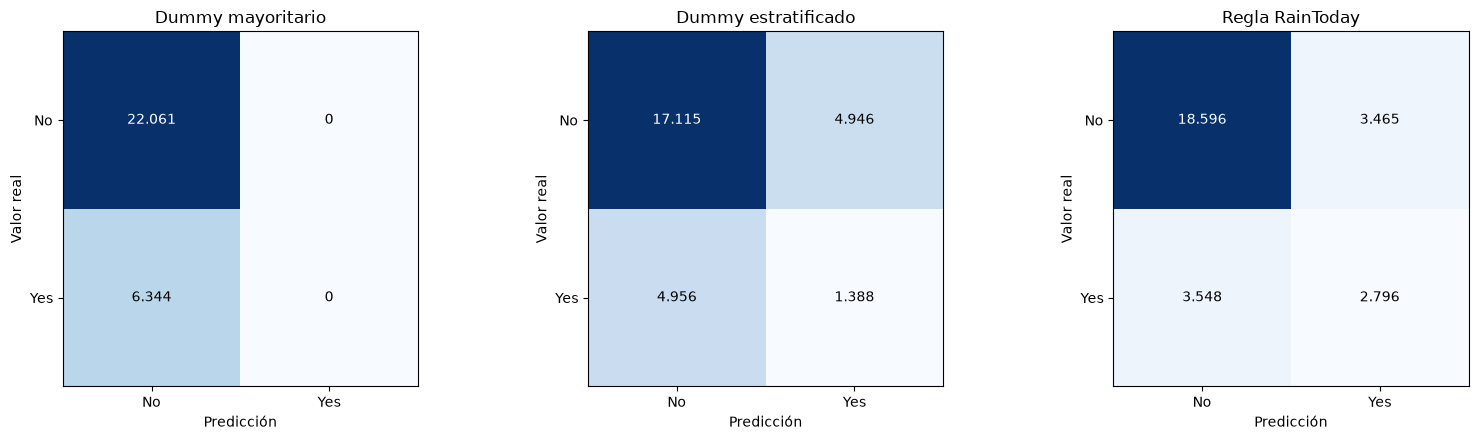

In [ ]:
# Grafico las matrices de confusión de los tres modelos base en prueba
predicciones_baseline = {
    "Dummy mayoritario": baselines["Dummy mayoritario"].predict(X_test_prep),
    "Dummy estratificado": baselines["Dummy estratificado"].predict(X_test_prep),
    "Regla RainToday": (X_test["RainToday"] == "Yes").astype(int).to_numpy(),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (nombre, y_pred) in zip(axes, predicciones_baseline.items()):
    matriz = confusion_matrix(y_test_bin, y_pred)
    graficar_matriz_confusion(ax, matriz, nombre)
plt.tight_layout()
plt.show()


Las matrices permiten ver qué tipo de error comete cada modelo base. El Dummy mayoritario manda todo a `No`: 22.061 verdaderos negativos y 6.344 falsos negativos, sin falsos positivos ni verdaderos positivos. Acierta la clase mayoritaria, pero no detecta ninguna lluvia.

El Dummy estratificado reparte los errores: 17.115 verdaderos negativos, 4.946 falsos positivos, 4.956 falsos negativos y 1.388 verdaderos positivos. La regla `RainToday` queda más equilibrada: 18.596 verdaderos negativos, 3.465 falsos positivos, 3.548 falsos negativos y 2.796 verdaderos positivos. Comparada con la regresión logística estándar (alrededor de 1.170 falsos positivos y 3.300 falsos negativos), la regla genera muchas más falsas alarmas y deja pasar alrededor de 240 días de lluvia más.

Un falso negativo es una lluvia sin aviso; un falso positivo, una falsa alarma. Para este problema nos importa más el falso negativo, pero tampoco queremos una precision tan baja que el pronóstico pierda utilidad.


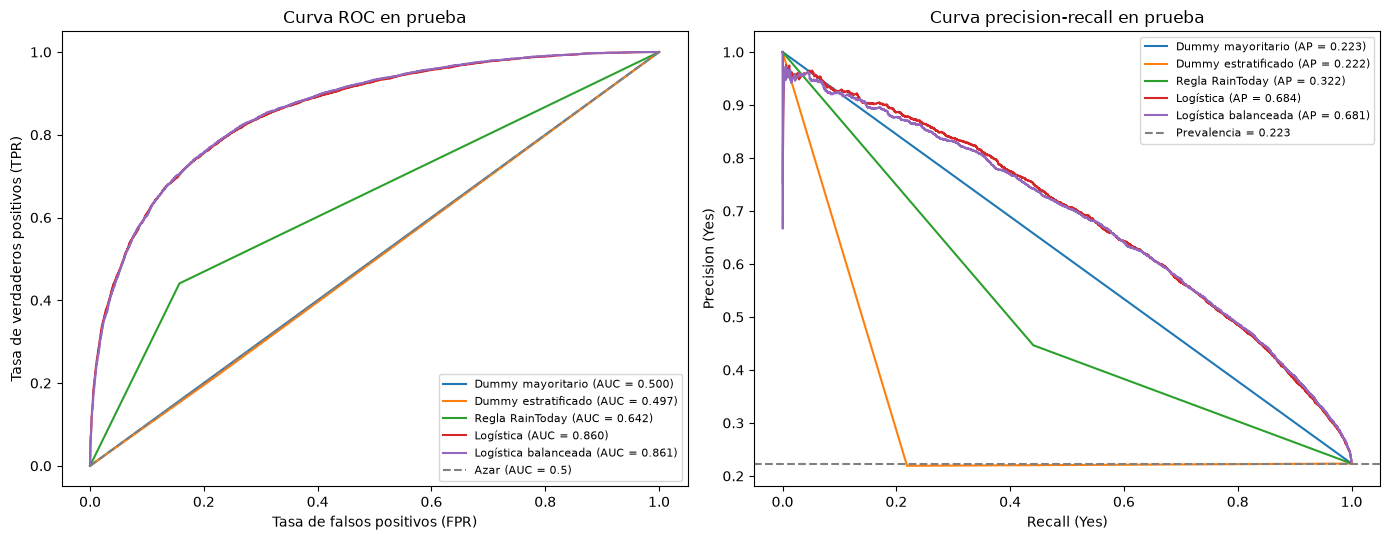

In [ ]:
# Comparo las curvas ROC y precision-recall de los modelos base y de las regresiones logísticas en prueba
from sklearn.metrics import precision_recall_curve
puntajes_prueba = {
    "Dummy mayoritario": baselines["Dummy mayoritario"].predict_proba(X_test_prep)[:, 1],
    "Dummy estratificado": baselines["Dummy estratificado"].predict_proba(X_test_prep)[:, 1],
    "Regla RainToday": (X_test["RainToday"] == "Yes").astype(int).to_numpy(),
}
for nombre, modelo in modelos.items():
    puntajes_prueba[nombre] = modelo.predict_proba(X_test_prep)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for nombre, puntaje in puntajes_prueba.items():
    fpr, tpr, _ = roc_curve(y_test_bin, puntaje)
    axes[0].plot(fpr, tpr, label=f"{nombre} (AUC = {roc_auc_score(y_test_bin, puntaje):.3f})")
    precision, recall, _ = precision_recall_curve(y_test_bin, puntaje)
    axes[1].plot(recall, precision, label=f"{nombre} (AP = {average_precision_score(y_test_bin, puntaje):.3f})")

axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Azar (AUC = 0.5)")
axes[0].set_xlabel("Tasa de falsos positivos (FPR)")
axes[0].set_ylabel("Tasa de verdaderos positivos (TPR)")
axes[0].set_title("Curva ROC en prueba")
axes[0].legend(loc="lower right", fontsize=8)

prevalencia = y_test_bin.mean()
axes[1].axhline(prevalencia, linestyle="--", color="gray", label=f"Prevalencia = {prevalencia:.3f}")
axes[1].set_xlabel("Recall (Yes)")
axes[1].set_ylabel("Precision (Yes)")
axes[1].set_title("Curva precision-recall en prueba")
axes[1].legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()


La curva ROC muestra qué tan bien el modelo separa los días con lluvia de los que no, para distintos umbrales. En los modelos base no aporta mucho, porque no dan una probabilidad útil. El Dummy mayoritario da siempre la misma probabilidad, así que su AUC queda en 0,5, igual que el azar. El Dummy estratificado también queda cerca de 0,5 porque sortea las clases. La regla `RainToday` solo devuelve `Yes` o `No`, no una probabilidad; por eso su ROC es un solo punto y su AUC da 0,642, el mismo valor que la balanced accuracy. En el gráfico, sklearn une ese punto con (0,0) y (1,1), pero la regla no tiene otros cortes para probar.

Para comparar estos modelos, la curva precision-recall es más útil porque `Yes` es la clase minoritaria. El average precision resume esa curva: cuanto más alto, mejor es el modelo para encontrar días de lluvia sin llenarse de falsos positivos. El Dummy mayoritario da 0,223, que es la prevalencia de `Yes`; el Dummy estratificado, ≈0,222; la regla, 0,322; y la regresión logística, ≈0,684.

Las líneas rectas de los modelos base solo unen pocos puntos: no tienen probabilidades intermedias. Por eso no hay que mirar el área dibujada, sino el average precision, que se calcula con los cortes reales.

Estas curvas son de prueba y las usamos solo para comparar. El umbral del ítem 2 se eligió en validación, no acá.


### ¿Hay fitting en un modelo base?

No en el sentido habitual. El Dummy no aprende parámetros y la regla es fija; no hay un entrenamiento que pueda memorizar los datos. Por eso no tiene sentido hablar de sobreajuste o subajuste como en la regresión logística. Lo que sí podemos mirar es que el comportamiento sea estable entre entrenamiento y prueba. En el Dummy mayoritario, la accuracy es 0,776 en entrenamiento y 0,777 en prueba; en la regla, 0,762 y 0,753. La diferencia es chica y no indica sobreajuste. Puede deberse a la proporción de clases en cada período, ya que prueba corresponde a fechas posteriores.

El análisis de fitting que importa sigue siendo el de la regresión logística del ítem 2: allí las métricas de train y prueba están cerca y no hay señales de sobreajuste. El modelo base no reemplaza ese análisis: sirve solo para marcar el piso.


### Conclusión del ítem 3

El Dummy mayoritario confirma que la accuracy sola es engañosa: 77,7 % de aciertos y 0 % de recall de `Yes`. La regla `RainToday` es un modelo base más exigente: con menos accuracy (0,753), mejora el MCC (0,285), la balanced accuracy (0,642) y el average precision (0,322). Aun así, queda lejos de la regresión logística estándar, que alcanza MCC ≈0,50, balanced accuracy ≈0,71 y average precision ≈0,68. La versión balanceada sube la balanced accuracy a ≈0,78, pero baja la precision.

Eso muestra que la regresión logística aprende algo más que la señal más obvia de `RainToday`. Los modelos base no son candidatos para el modelo final: son referencias. El ítem 3 no necesita pipeline ni optimización de umbral; esas decisiones aparecen en los próximos ítems.


## 4. Optimización de hiperparámetros

En este ítem buscamos mejorar la regresión logística del ítem 2 sin usar el conjunto de prueba. Para eso armamos un pipeline que repite el preprocesamiento del ítem 2 dentro de cada partición: `RobustScaler`, imputación de numéricas con la mediana, `"Faltante"` en categóricas y one-hot con `drop_first=True`. Así, en cada fold los parámetros se calculan solo con el tramo de entrenamiento correspondiente y no se filtra información.

Como los datos son temporales, no usamos un `KFold` aleatorio: ordenamos por fecha y armamos 4 cortes con `TimeSeriesSplit` sobre las fechas únicas. Cada corte entrena con el pasado y valida con el tramo siguiente. Después llevamos esos cortes a las filas, así una misma fecha no queda en entrenamiento y validación. Todos los candidatos usan los mismos cortes y el conjunto de prueba queda intacto hasta la evaluación final.

Optimizamos `C` (en scikit-learn es el inverso de lambda: cuanto más chico, más regulariza) y `class_weight` (`None` o `"balanced"`). No tocamos el solver ni la penalización: el ítem 2 ya mostró que `lbfgs` con L2 converge con `max_iter=1000`, y cambiarlos agregaría costo sin una hipótesis clara. Usamos `GridSearchCV` porque tenemos dos hiperparámetros y una grilla chica: seis valores de `C` (0,01 a 1000) por dos opciones de `class_weight`, 12 combinaciones. La cátedra recomienda grid para uno o dos hiperparámetros; random search queda para espacios más grandes. Probamos `C` en potencias de 10 para cubrir desde mucha hasta casi ninguna regularización. La métrica de selección es average precision, la misma que venimos usando para comparar modelos con clases desbalanceadas. También guardamos el score de entrenamiento para revisar sobreajuste.


In [ ]:
# Armo el pipeline y busco hiperparámetros con una grilla y validación temporal.
import warnings

import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.preprocessing import OneHotEncoder

# El CSV no está ordenado por fecha; ordeno solo entrenamiento para que TimeSeriesSplit respete el tiempo.
fechas_train_ordenadas = fechas_train.sort_values()
X_train_ordenado = X_train.loc[fechas_train_ordenadas.index]
y_train_ordenado = y_train_bin.loc[fechas_train_ordenadas.index]

# Los cortes se arman con fechas únicas y después se traducen a filas.
fechas_unicas = np.sort(fechas_train_ordenadas.unique())
folds_temporales = []
for fechas_entrenamiento_idx, fechas_validacion_idx in TimeSeriesSplit(n_splits=4).split(fechas_unicas):
    fechas_entrenamiento = fechas_unicas[fechas_entrenamiento_idx]
    fechas_validacion = fechas_unicas[fechas_validacion_idx]
    filas_entrenamiento = np.flatnonzero(
        fechas_train_ordenadas.isin(fechas_entrenamiento).to_numpy()
    )
    filas_validacion = np.flatnonzero(
        fechas_train_ordenadas.isin(fechas_validacion).to_numpy()
    )
    folds_temporales.append((filas_entrenamiento, filas_validacion))

# Mantengo el orden del ítem 2: primero escalo y después imputo con la mediana.
pipeline_numerico = Pipeline(steps=[
    ("escalador", RobustScaler()),
    ("imputador", SimpleImputer(strategy="median")),
])
pipeline_categorico = Pipeline(steps=[
    ("imputador", SimpleImputer(strategy="constant", fill_value="Faltante")),
    ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore")),
])
preprocesador = ColumnTransformer(transformers=[
    ("numericas", pipeline_numerico, columnas_predictoras_numericas),
    ("categoricas", pipeline_categorico, columnas_categoricas),
])

pipeline_logistica = Pipeline(steps=[
    ("preprocesamiento", preprocesador),
    ("modelo", LogisticRegression(max_iter=1000)),
])

espacio_busqueda = {
    "modelo__C": [0.01, 0.1, 1, 10, 100, 1000],
    "modelo__class_weight": [None, "balanced"],
}

busqueda = GridSearchCV(
    estimator=pipeline_logistica,
    param_grid=espacio_busqueda,
    scoring="average_precision",
    cv=folds_temporales,
    n_jobs=1,
    return_train_score=True,
    refit=True,
)

# En algunos folds aparecen categorías que no estaban en el entrenamiento.
# handle_unknown="ignore" las codifica como cero; silencio solo ese aviso esperado.
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="Found unknown categories")
    busqueda.fit(X_train_ordenado, y_train_ordenado)

print(f"Mejor AP en validación cruzada: {busqueda.best_score_:.4f}")
print(f"Mejor C: {busqueda.best_params_['modelo__C']:.4f}")
print(f"class_weight: {busqueda.best_params_['modelo__class_weight']}")


Mejor AP en validación cruzada: 0.7025
Mejor C: 0.1000
class_weight: None


### Resultados de la validación cruzada

La tabla muestra las 10 mejores combinaciones. `AP validación` es el average precision promedio en los 4 cortes; `AP entrenamiento` es el promedio en los tramos de entrenamiento de cada corte. Los cortes se definen por fecha, no por fila. La grilla de `C` usa potencias de 10. En total se ajustaron 48 modelos: 12 combinaciones por 4 folds.


In [ ]:
# Muestro las mejores combinaciones de la búsqueda.
resultados_cv = pd.DataFrame(busqueda.cv_results_)
tabla_cv = resultados_cv.sort_values("rank_test_score")[[
    "rank_test_score",
    "mean_test_score",
    "std_test_score",
    "mean_train_score",
    "param_modelo__C",
    "param_modelo__class_weight",
]].head(10).reset_index(drop=True).copy()

tabla_cv["param_modelo__C"] = tabla_cv["param_modelo__C"].astype(float).round(4)
tabla_cv["param_modelo__class_weight"] = tabla_cv["param_modelo__class_weight"].fillna("None")
tabla_cv = tabla_cv.rename(columns={
    "rank_test_score": "posición",
    "mean_test_score": "AP validación",
    "std_test_score": "desvío validación",
    "mean_train_score": "AP entrenamiento",
    "param_modelo__C": "C",
    "param_modelo__class_weight": "class_weight",
})
display(tabla_cv.round(4))


,posición,AP validación,desvío validación,AP entrenamiento,C,class_weight
0,1,0.7025,0.0147,0.7179,0.1,None
1,2,0.7019,0.0148,0.7203,1.0,None
2,3,0.7014,0.0149,0.7208,10.0,None
3,4,0.7012,0.0149,0.7208,100.0,None
4,5,0.7010,0.0149,0.7208,1000.0,None
5,6,0.6996,0.0147,0.7140,0.1,balanced
6,7,0.6989,0.0150,0.7155,1.0,balanced
7,8,0.6981,0.0153,0.7156,10.0,balanced
8,9,0.6980,0.0153,0.7157,100.0,balanced
9,10,0.6980,0.0154,0.7156,1000.0,balanced


### Evaluación del mejor modelo

Reentrenamos el mejor pipeline con todo el entrenamiento y lo evaluamos una sola vez en prueba. Para comparar, incluimos las métricas de los dos modelos del ítem 2. El umbral sigue siendo 0,5: en este ítem optimizamos hiperparámetros, no el punto de corte.


In [ ]:
# Evalúo el mejor pipeline en entrenamiento y prueba.
mejor_modelo = busqueda.best_estimator_

filas_item4 = []
for conjunto, (X_conjunto, y_conjunto) in {
    "Entrenamiento": (X_train_ordenado, y_train_ordenado),
    "Prueba": (X_test, y_test_bin),
}.items():
    y_pred = mejor_modelo.predict(X_conjunto)
    y_score = mejor_modelo.predict_proba(X_conjunto)[:, 1]
    filas_item4.append({
        "modelo": "Logística optimizada",
        "conjunto": conjunto,
        **calcular_metricas(y_conjunto, y_pred, y_score),
    })

metricas_item4 = pd.DataFrame(filas_item4).set_index(["modelo", "conjunto"])
display(metricas_item4.round(3))

comparacion_item4 = pd.concat([metricas, metricas_item4])
display(comparacion_item4.xs("Prueba", level="conjunto").round(3))


accuracy  precision (Yes)  recall (Yes)  \
modelo               conjunto                                                 
Logística optimizada Entrenamiento     0.850            0.732         0.519   
                     Prueba            0.842            0.720         0.477   

                                    F1 (Yes)  recall (No)    AUC  \
modelo               conjunto                                      
Logística optimizada Entrenamiento     0.608        0.945  0.875   
                     Prueba            0.574        0.947  0.860   

                                    balanced accuracy    MCC  \
modelo               conjunto                                  
Logística optimizada Entrenamiento              0.732  0.530   
                     Prueba                     0.712  0.497   

                                    average precision  
modelo               conjunto                          
Logística optimizada Entrenamiento              0.710  
                     Prueba                     0.684

,accuracy,precision (Yes),recall (Yes),F1 (Yes),recall (No),AUC,balanced accuracy,MCC,average precision
modelo,,,,,,,,,
Logística,0.842,0.721,0.479,0.575,0.947,0.860,0.713,0.498,0.684
Logística balanceada,0.796,0.531,0.747,0.620,0.810,0.861,0.778,0.499,0.681
Logística optimizada,0.842,0.720,0.477,0.574,0.947,0.860,0.712,0.497,0.684


### Conclusión del ítem 4

La grilla eligió `C=0,1` y `class_weight=None`. La diferencia con `C=1` es de solo 0,0006 en el AP medio, muy por debajo del desvío entre folds (≈0,015). Con `C=10`, `C=100` y `C=1000` el AP baja un poco más, y con `class_weight="balanced"` queda por debajo en todos los casos. Por eso no hay evidencia de una mejora real; la configuración por defecto del ítem 2 ya era razonable. El AP de entrenamiento fue ≈0,710, el AP medio en validación cruzada ≈0,702 y el AP de prueba ≈0,684. La caída es chica y no sugiere sobreajuste. En prueba, las métricas quedan casi iguales a las de la regresión logística estándar: accuracy ≈0,842, precision ≈0,720, recall ≈0,477, F1 ≈0,574, MCC ≈0,497, AUC ≈0,860 y AP ≈0,684.

`class_weight="balanced"` sube el recall pero baja la precision y no mejora el AP. En este problema, el umbral pesa más que `C`, y eso ya se trabajó en el ítem 2.

El pipeline se ajusta dentro de cada fold, así que la imputación, el escalado y el one-hot no usan información de validación. El conjunto de prueba se usó una sola vez, al final. El mejor pipeline queda en `mejor_modelo` para los próximos ítems.


## 5. Explicabilidad de los modelos

Para este ítem explicamos el mejor pipeline del ítem 4, sin volver a entrenarlo. El explicador usa una muestra de entrenamiento como referencia (background) y explica observaciones del conjunto de prueba, que se reserva para la evaluación. Para que las figuras globales sean legibles, usamos una muestra reproducible de hasta 2.000 filas de prueba; los dos ejemplos locales se seleccionan del conjunto de prueba completo.

Aplicamos SHAP al componente lineal de la regresión logística, después del preprocesamiento. La salida explicada es la función de decisión en log-odds: un valor SHAP positivo empuja la predicción hacia RainTomorrow = Yes y uno negativo hacia No. La suma del valor base y los aportes SHAP reconstruye esa salida. Usamos la máscara Independent: el cálculo trata las features transformadas como independientes al repartir el aporte. Agrupamos las dummies por predictor para las lecturas por variable. SHAP describe el modelo, no una relación causal.

Las variables categóricas se expanden en columnas one-hot. En los waterfalls locales agrupamos sus aportes para volver a las variables originales; el beeswarm muestra las columnas transformadas y sus valores. 



C:\Users\Tomas\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Version de SHAP: 0.54.1
Background de entrenamiento: (512, 114)
Observaciones de prueba explicadas globalmente: 2000


,fecha,Location,clase real,clase predicha,probabilidad de lluvia
caso,,,,,
"Lluvia, mayor confianza",2016-06-05,Sydney,Yes,Yes,0.999
"Sin lluvia, mayor confianza",2016-04-24,Woomera,No,No,0.001


Cinco variables con mayor importancia media absoluta:


,SHAP medio absoluto (log-odds)
Humidity3pm,0.901853
Pressure3pm,0.816776
WindGustSpeed,0.543585
Pressure9am,0.543556
MaxTemp,0.298008


Cinco variables con menor importancia media absoluta:


,SHAP medio absoluto (log-odds)
Evaporation,0.013480
Cloud9am,0.014057
Rainfall,0.036145
Humidity9am,0.060355
WindGustDir,0.068486


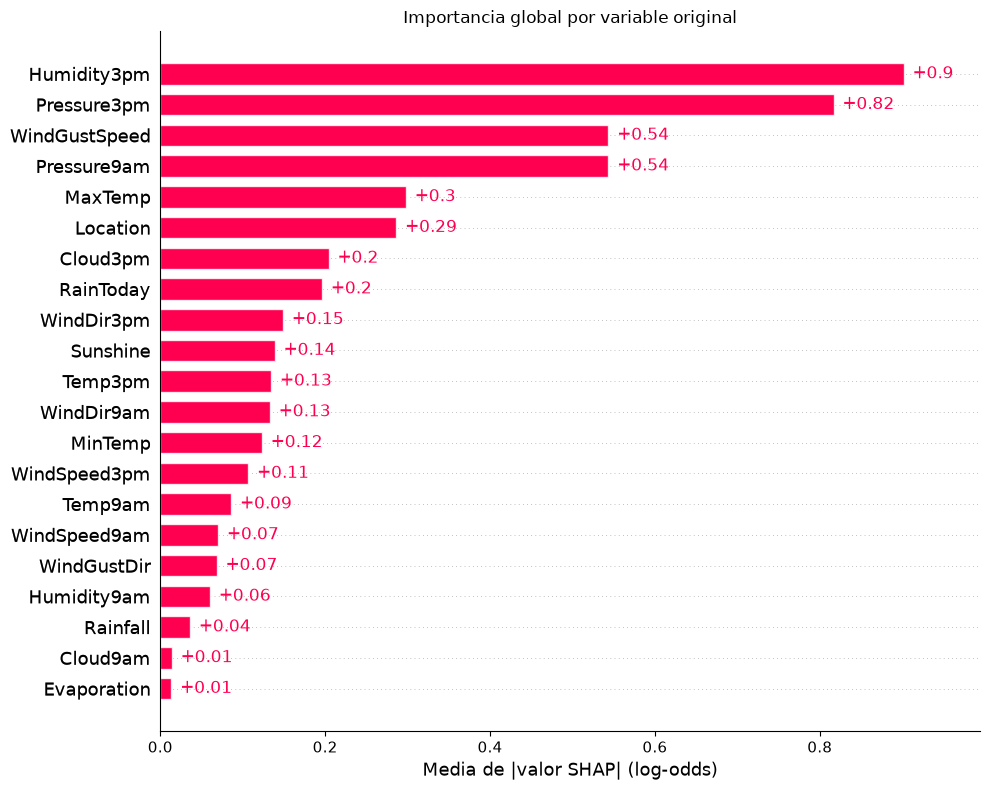

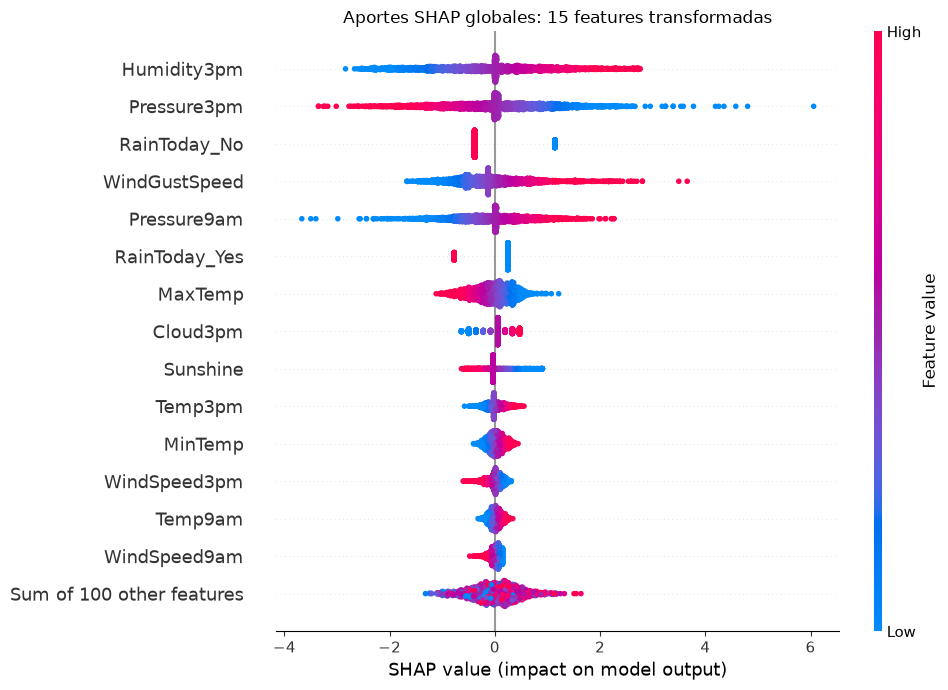

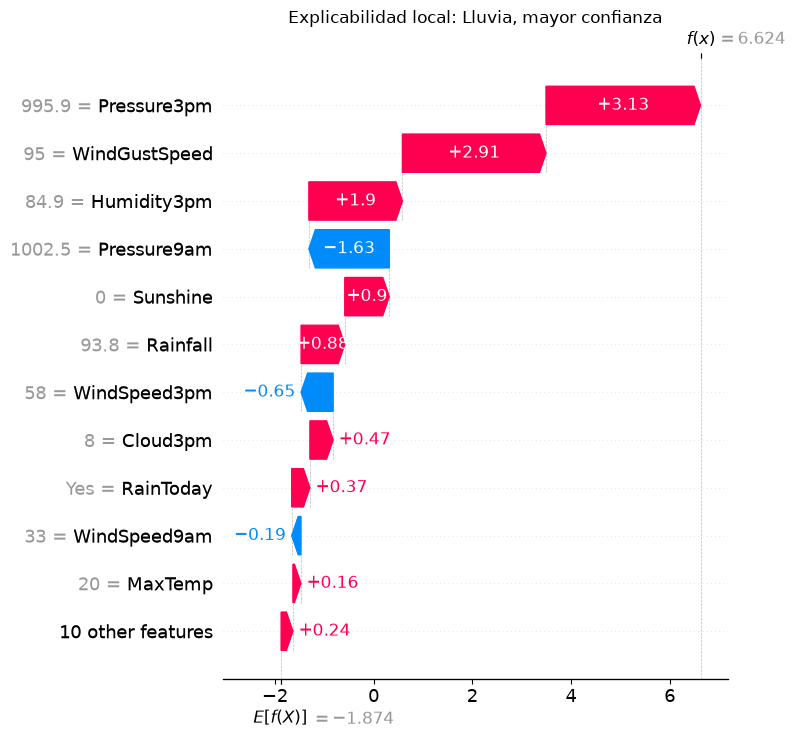

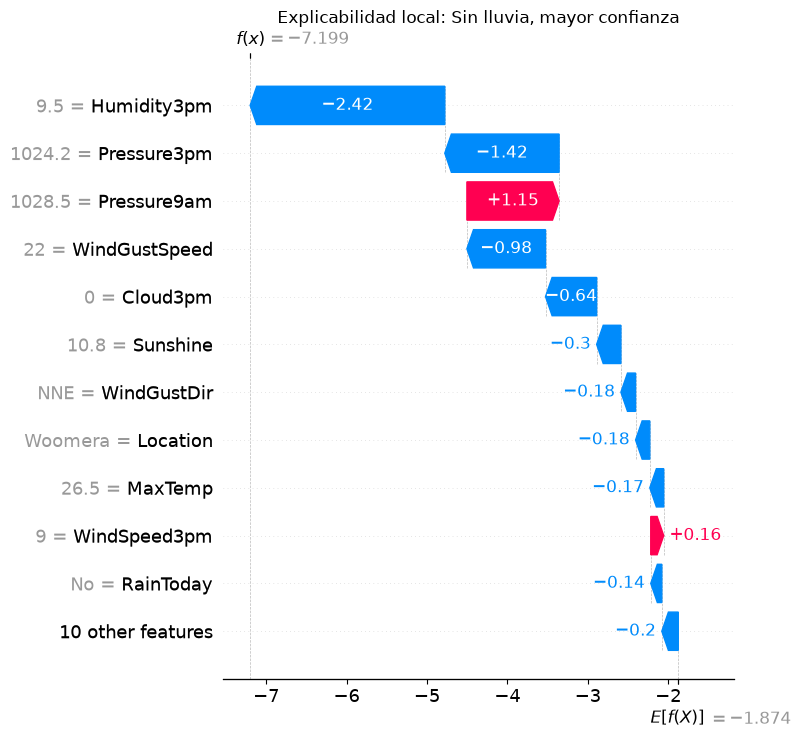

Error maximo de reconstruccion SHAP de decision_function: 2.66e-15


### Lectura de las explicaciones

En la muestra de prueba, las variables con mayor importancia media absoluta agrupada son: Humidity3pm (0.902), Pressure3pm (0.817), WindGustSpeed (0.544), Pressure9am (0.544), MaxTemp (0.298). Las de menor importancia son: Evaporation (0.013), Cloud9am (0.014), Rainfall (0.036), Humidity9am (0.060), WindGustDir (0.068). Esta medida promedia la magnitud de los aportes por observación; no indica si una variable aumenta o reduce la lluvia.

En el caso local con lluvia, los aportes que más empujan hacia Yes son Pressure3pm (+3.131), WindGustSpeed (+2.910), Humidity3pm (+1.895); los que más empujan hacia No son Pressure9am (-1.629), WindSpeed3pm (-0.649), WindSpeed9am (-0.186). En el caso local sin lluvia, los aportes que más empujan hacia Yes son Pressure9am (+1.147), WindSpeed3pm (+0.161), WindDir3pm (+0.062); los que más empujan hacia No son Humidity3pm (-2.420), Pressure3pm (-1.422), WindGustSpeed (-0.978). Los valores positivos y negativos se interpretan en log-odds y corresponden a los dos waterfalls.

El beeswarm complementa la importancia agrupada: cada punto representa una observación de prueba, su posición muestra la direccion y magnitud del aporte, y el color indica el valor de la feature transformada. La explicación describe el comportamiento de esta regresión logística; no demuestra causalidad.

In [ ]:
# Explico el componente lineal del mejor pipeline usando entrenamiento como background.
import numpy as np
import shap
from IPython.display import Markdown, display

preprocesador_shap = mejor_modelo.named_steps["preprocesamiento"]
modelo_shap = mejor_modelo.named_steps["modelo"]
nombres_features_shap = preprocesador_shap.get_feature_names_out()
nombres_features_visibles = [
    nombre.split("__", 1)[-1] if "__" in nombre else nombre
    for nombre in nombres_features_shap
]

def matriz_densa_shap(matriz):
    # ColumnTransformer puede devolver una matriz dispersa por las columnas one-hot.
    return matriz.toarray() if hasattr(matriz, "toarray") else np.asarray(matriz)

n_background_shap = min(512, len(X_train_ordenado))
X_background_shap = X_train_ordenado.sample(n=n_background_shap, random_state=42)
X_background_transformado = matriz_densa_shap(
    preprocesador_shap.transform(X_background_shap)
)

n_global_shap = min(2000, len(X_test))
X_test_global_shap = X_test.sample(n=n_global_shap, random_state=42)
X_test_global_transformado = matriz_densa_shap(
    preprocesador_shap.transform(X_test_global_shap)
)

mascara_shap = shap.maskers.Independent(
    X_background_transformado,
    max_samples=n_background_shap,
)
explicador_shap = shap.Explainer(
    modelo_shap,
    mascara_shap,
    feature_names=nombres_features_visibles,
    algorithm="linear",
    seed=42,
)
explicaciones_globales = explicador_shap(X_test_global_transformado)

print("Version de SHAP:", shap.__version__)
print("Background de entrenamiento:", X_background_transformado.shape)
print("Observaciones de prueba explicadas globalmente:", X_test_global_transformado.shape[0])

# Selecciono un ejemplo lluvioso y uno seco, ambos correctamente clasificados y de alta confianza.
probabilidades_yes_test = mejor_modelo.predict_proba(X_test)[:, 1]
predicciones_test_shap = mejor_modelo.predict(X_test)
clases_reales_test = y_test_bin.to_numpy()

posiciones_yes_correctos = np.flatnonzero(
    (clases_reales_test == 1) & (predicciones_test_shap == 1)
)
posiciones_no_correctos = np.flatnonzero(
    (clases_reales_test == 0) & (predicciones_test_shap == 0)
)
if len(posiciones_yes_correctos) == 0 or len(posiciones_no_correctos) == 0:
    raise ValueError("No se encontraron ejemplos correctamente clasificados de ambas clases.")

pos_yes = posiciones_yes_correctos[
    np.argmax(probabilidades_yes_test[posiciones_yes_correctos])
]
pos_no = posiciones_no_correctos[
    np.argmin(probabilidades_yes_test[posiciones_no_correctos])
]
indices_locales_shap = [X_test.index[pos_yes], X_test.index[pos_no]]
X_test_local_shap = X_test.loc[indices_locales_shap]
X_test_local_transformado = matriz_densa_shap(
    preprocesador_shap.transform(X_test_local_shap)
)
explicaciones_locales = explicador_shap(X_test_local_transformado)

resumen_casos_locales = []
for nombre_caso, posicion, indice in [
    ("Lluvia, mayor confianza", pos_yes, indices_locales_shap[0]),
    ("Sin lluvia, mayor confianza", pos_no, indices_locales_shap[1]),
]:
    resumen_casos_locales.append({
        "caso": nombre_caso,
        "fecha": fechas_test.loc[indice].date(),
        "Location": X_test.loc[indice, "Location"],
        "clase real": "Yes" if clases_reales_test[posicion] == 1 else "No",
        "clase predicha": "Yes" if predicciones_test_shap[posicion] == 1 else "No",
        "probabilidad de lluvia": probabilidades_yes_test[posicion],
    })
display(pd.DataFrame(resumen_casos_locales).set_index("caso").round({
    "probabilidad de lluvia": 3,
}))

# Agrupo las columnas one-hot por predictor original, preservando la suma aditiva SHAP.
def variable_original_shap(nombre_feature):
    nombre = nombre_feature.split("__", 1)[-1] if "__" in nombre_feature else nombre_feature
    if nombre in columnas_predictoras_numericas:
        return nombre
    for variable in columnas_categoricas:
        if nombre.startswith(variable + "_"):
            return variable
    raise ValueError(f"No se pudo asociar la feature transformada {nombre_feature!r}.")

posiciones_predictoras = {
    variable: posicion
    for posicion, variable in enumerate(columnas_predictoras)
}
variables_por_feature_shap = [
    variable_original_shap(nombre)
    for nombre in nombres_features_shap
]

def agrupar_aportes_por_predictor(valores):
    agrupados = np.zeros((valores.shape[0], len(columnas_predictoras)))
    for posicion_feature, variable in enumerate(variables_por_feature_shap):
        agrupados[:, posiciones_predictoras[variable]] += valores[:, posicion_feature]
    return agrupados

valores_globales_agrupados = agrupar_aportes_por_predictor(
    explicaciones_globales.values
)
explicaciones_globales_por_variable = shap.Explanation(
    values=valores_globales_agrupados,
    base_values=explicaciones_globales.base_values,
    feature_names=columnas_predictoras,
)

# Muestro la importancia media absoluta agrupada en las variables originales.
importancia_shap = pd.Series(
    np.abs(valores_globales_agrupados).mean(axis=0),
    index=columnas_predictoras,
    name="SHAP medio absoluto (log-odds)",
).sort_values(ascending=False)
print("Cinco variables con mayor importancia media absoluta:")
display(importancia_shap.head(5).to_frame())
print("Cinco variables con menor importancia media absoluta:")
display(importancia_shap.tail(5).sort_values().to_frame())

ax_importancia_shap = shap.plots.bar(
    explicaciones_globales_por_variable,
    max_display=len(columnas_predictoras),
    show=False,
)
ax_importancia_shap.figure.set_size_inches(10, 8)
ax_importancia_shap.set_title("Importancia global por variable original")
ax_importancia_shap.set_xlabel("Media de |valor SHAP| (log-odds)")
plt.tight_layout()
plt.show()

# El beeswarm muestra la distribucion y direccion de los aportes de las features transformadas.
ax_beeswarm_shap = shap.plots.beeswarm(
    explicaciones_globales,
    max_display=15,
    show=False,
    plot_size=(10, 7),
)
ax_beeswarm_shap.set_title("Aportes SHAP globales: 15 features transformadas")
plt.tight_layout()
plt.show()

# En cada waterfall, sumo los aportes de las dummies y muestro el valor original del predictor.
valores_locales_agrupados = agrupar_aportes_por_predictor(
    explicaciones_locales.values
)
datos_locales_visibles = X_test_local_shap[columnas_predictoras].copy().astype(object)
for columna in columnas_predictoras:
    datos_locales_visibles[columna] = datos_locales_visibles[columna].where(
        datos_locales_visibles[columna].notna(),
        "Faltante (imputado)" if columna in columnas_predictoras_numericas else "Faltante",
    )

explicaciones_locales_por_variable = shap.Explanation(
    values=valores_locales_agrupados,
    base_values=explicaciones_locales.base_values,
    data=datos_locales_visibles.to_numpy(dtype=object),
    feature_names=columnas_predictoras,
)

for posicion, nombre_caso in enumerate([
    "Lluvia, mayor confianza",
    "Sin lluvia, mayor confianza",
]):
    ax_local = shap.plots.waterfall(
        explicaciones_locales_por_variable[posicion],
        max_display=12,
        show=False,
    )
    ax_local.set_title(f"Explicabilidad local: {nombre_caso}")
    plt.tight_layout()
    plt.show()

salidas_modelo_locales = modelo_shap.decision_function(X_test_local_transformado)
error_aditivo_shap = np.max(np.abs(
    explicaciones_locales.base_values
    + explicaciones_locales.values.sum(axis=1)
    - salidas_modelo_locales
))
print(f"Error maximo de reconstruccion SHAP de decision_function: {error_aditivo_shap:.2e}")

def aportes_direccionales_shap(fila_aportes, positivos=True, cantidad=3):
    posiciones = [
        i for i, valor in enumerate(fila_aportes)
        if (valor > 0 if positivos else valor < 0)
    ]
    posiciones.sort(key=lambda i: fila_aportes[i], reverse=positivos)
    return ", ".join(
        f"{columnas_predictoras[i]} ({fila_aportes[i]:+.3f})"
        for i in posiciones[:cantidad]
    ) or "sin aportes en esta direccion"

top_variables_texto = ", ".join(
    f"{variable} ({valor:.3f})"
    for variable, valor in importancia_shap.head(5).items()
)
variables_menor_importancia_texto = ", ".join(
    f"{variable} ({valor:.3f})"
    for variable, valor in importancia_shap.tail(5).sort_values().items()
)
aporte_yes_positivo = aportes_direccionales_shap(valores_locales_agrupados[0], positivos=True)
aporte_yes_negativo = aportes_direccionales_shap(valores_locales_agrupados[0], positivos=False)
aporte_no_positivo = aportes_direccionales_shap(valores_locales_agrupados[1], positivos=True)
aporte_no_negativo = aportes_direccionales_shap(valores_locales_agrupados[1], positivos=False)

texto_observaciones_shap = (
    "### Lectura de las explicaciones\n\n"
    f"En la muestra de prueba, las variables con mayor importancia media absoluta agrupada son: {top_variables_texto}. "
    f"Las de menor importancia son: {variables_menor_importancia_texto}. "
    "Esta medida promedia la magnitud de los aportes por observaci\u00f3n; no indica si una variable aumenta o reduce la lluvia.\n\n"
    f"En el caso local con lluvia, los aportes que m\u00e1s empujan hacia Yes son {aporte_yes_positivo}; "
    f"los que m\u00e1s empujan hacia No son {aporte_yes_negativo}. "
    f"En el caso local sin lluvia, los aportes que m\u00e1s empujan hacia Yes son {aporte_no_positivo}; "
    f"los que m\u00e1s empujan hacia No son {aporte_no_negativo}. "
    "Los valores positivos y negativos se interpretan en log-odds y corresponden a los dos waterfalls.\n\n"
    "El beeswarm complementa la importancia agrupada: cada punto representa una observaci\u00f3n de prueba, "
    "su posici\u00f3n muestra la direccion y magnitud del aporte, y el color indica el valor de la feature transformada. "
    "La explicaci\u00f3n describe el comportamiento de esta regresi\u00f3n log\u00edstica; no demuestra causalidad."
)
display(Markdown(texto_observaciones_shap))
